
<a id="lb"></a>

# <div style="background-color: #FF5733; font-family: 'Gill Sans', sans-serif; font-size: 36px; color: #ffffff; text-align: center; border-radius: 20px; padding: 20px; border: 2px solid #ffffff; box-shadow: 0 4px 10px rgba(0, 0, 0, 0.2);"><b>Predicting Student Success</b></div>


# <font color='289C4E'>Table of contents<font><a class='anchor' id='top'></a>
1. [Problem Understanding](#Problem)
2. [Data Exploration](#Exploration)
3. [Data Preprocessing](#Preprocessing) 
4. [EDA](#EDA)
5. [Label Encoding](#Encoding)
6. [Feature Engineering](#Engineering)
7. [Patterns in student Performance](#Performance)
8. [Choosing Target](#Target)
9. [Building models](#Building)
10. [Model Performance Comparison](#Comparison)
11. [Feature importance](#importance)
12. [Decision](#Decision)
13. [Best Model Save](#Save)
14. [Save to a CSV file](#CSV)


<a class='anchor' id="Problem"></a> [↑](#top)

# <div style="background-color: #FF5733; font-family: 'Gill Sans', sans-serif; font-size: 36px; color: #ffffff; text-align: center; border-radius: 20px; padding: 20px; border: 2px solid #ffffff; box-shadow: 0 4px 10px rgba(0, 0, 0, 0.2);"><b>1. Problem Understanding</b></div>


### Importing Librarires

In [1]:
# Importing necessary libraries for data analysis and machine learning model building.
import pandas as pd               # Library for data manipulation and analysis
import numpy as np                # Library for numerical computing
import matplotlib.pyplot as plt   # Library for data visualization
import seaborn as sns             # Library for statistical data visualization



In [2]:
# Importing machine learning algorithms and evaluation metrics from scikit-learn
from sklearn.ensemble import RandomForestRegressor           # Random Forest Regressor
from sklearn.model_selection import train_test_split, ShuffleSplit         # Train-test split
from sklearn.linear_model import LogisticRegression          # Logistic Regression
from sklearn.neural_network import MLPClassifier             # Multi-layer Perceptron Classifier
from sklearn.neighbors import KNeighborsClassifier           # k-Nearest Neighbors Classifier
from sklearn.svm import SVC, LinearSVC, NuSVC                # Support Vector Classifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier  # Ensemble classifiers
from sklearn.naive_bayes import GaussianNB                   # Gaussian Naive Bayes Classifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis  # Discriminant Analysis
from sklearn import tree                                     # Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier              # Decision Tree Classifier
from sklearn.metrics import mean_absolute_error

In [3]:
# Importing metrics for model evaluation
from sklearn import metrics                                  # General metrics
from sklearn.metrics import accuracy_score, log_loss         # Accuracy and Log Loss
from sklearn.metrics import classification_report, confusion_matrix, auc, roc_curve, roc_auc_score  # Classification metrics
from sklearn import metrics # measure classification performance

from sklearn.preprocessing import StandardScaler,MinMaxScaler,RobustScaler
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.model_selection import cross_validate
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, auc, roc_curve, roc_auc_score, log_loss, precision_score, recall_score, f1_score, make_scorer


<a class='anchor' id='Exploration'></a>[↑](#top)
# <div style="background-color: #FF5733; font-family: 'Gill Sans', sans-serif; font-size: 36px; color: #ffffff; text-align: center; border-radius: 20px; padding: 20px; border: 2px solid #ffffff; box-shadow: 0 4px 10px rgba(0, 0, 0, 0.2);"><b>  2.  Data Exploration </b></div>


## Importing the dataset

In [4]:
#### Importing the dataset
df = pd.read_excel(r'c:/Users/ayoub/Emines/Projet info CPi2a/StudentPerformanceFactors.xlsx')
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [5]:
main_df = df
main_df

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


### Number of records and features in the dataset

In [6]:
df.shape

(6607, 20)

### Describing the dataset in short

In [7]:
df.describe(include='all')

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
count,6607.000000,6607.000000,6607,6607,6607,6607.00000,6607.000000,6607,6607,6607.000000,6607,6529,6607,6607,6607.000000,6607,6517,6540,6607,6607.000000
unique,NaN,NaN,3,3,2,NaN,NaN,3,2,NaN,3,3,2,3,NaN,2,3,3,2,NaN
top,NaN,NaN,Medium,Medium,Yes,NaN,NaN,Medium,Yes,NaN,Low,Medium,Public,Positive,NaN,No,High School,Near,Male,NaN
freq,NaN,NaN,3362,3319,3938,NaN,NaN,3351,6108,NaN,2672,3925,4598,2638,NaN,5912,3223,3884,3814,NaN
mean,19.975329,79.977448,NaN,NaN,NaN,7.02906,75.070531,NaN,NaN,1.493719,NaN,NaN,NaN,NaN,2.967610,NaN,NaN,NaN,NaN,67.235659
std,5.990594,11.547475,NaN,NaN,NaN,1.46812,14.399784,NaN,NaN,1.230570,NaN,NaN,NaN,NaN,1.031231,NaN,NaN,NaN,NaN,3.890456
min,1.000000,60.000000,NaN,NaN,NaN,4.00000,50.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,55.000000
25%,16.000000,70.000000,NaN,NaN,NaN,6.00000,63.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,65.000000
50%,20.000000,80.000000,NaN,NaN,NaN,7.00000,75.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,3.000000,NaN,NaN,NaN,NaN,67.000000
75%,24.000000,90.000000,NaN,NaN,NaN,8.00000,88.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,4.000000,NaN,NaN,NaN,NaN,69.000000


### Describing the dataset in other way

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

<a class='anchor' id='Preprocessing'></a>[↑](#top)

# <div style="background-color: #FF5733; font-family: 'Gill Sans', sans-serif; font-size: 36px; color: #ffffff; text-align: center; border-radius: 20px; padding: 20px; border: 2px solid #ffffff; box-shadow: 0 4px 10px rgba(0, 0, 0, 0.2);"><b>  3. Data Preprocessing </b></div>


### show the data type of all attributes

In [9]:
df.dtypes

Hours_Studied                  int64
Attendance                     int64
Parental_Involvement          object
Access_to_Resources           object
Extracurricular_Activities    object
Sleep_Hours                    int64
Previous_Scores                int64
Motivation_Level              object
Internet_Access               object
Tutoring_Sessions              int64
Family_Income                 object
Teacher_Quality               object
School_Type                   object
Peer_Influence                object
Physical_Activity              int64
Learning_Disabilities         object
Parental_Education_Level      object
Distance_from_Home            object
Gender                        object
Exam_Score                     int64
dtype: object

### Checking Null values

In [10]:
print(df.isnull() .sum())

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64


In [11]:
## Checking null values in %
df.isnull().sum() / df.shape[0] * 100

Hours_Studied                 0.000000
Attendance                    0.000000
Parental_Involvement          0.000000
Access_to_Resources           0.000000
Extracurricular_Activities    0.000000
Sleep_Hours                   0.000000
Previous_Scores               0.000000
Motivation_Level              0.000000
Internet_Access               0.000000
Tutoring_Sessions             0.000000
Family_Income                 0.000000
Teacher_Quality               1.180566
School_Type                   0.000000
Peer_Influence                0.000000
Physical_Activity             0.000000
Learning_Disabilities         0.000000
Parental_Education_Level      1.362192
Distance_from_Home            1.014076
Gender                        0.000000
Exam_Score                    0.000000
dtype: float64

<Figure size 1000x600 with 0 Axes>

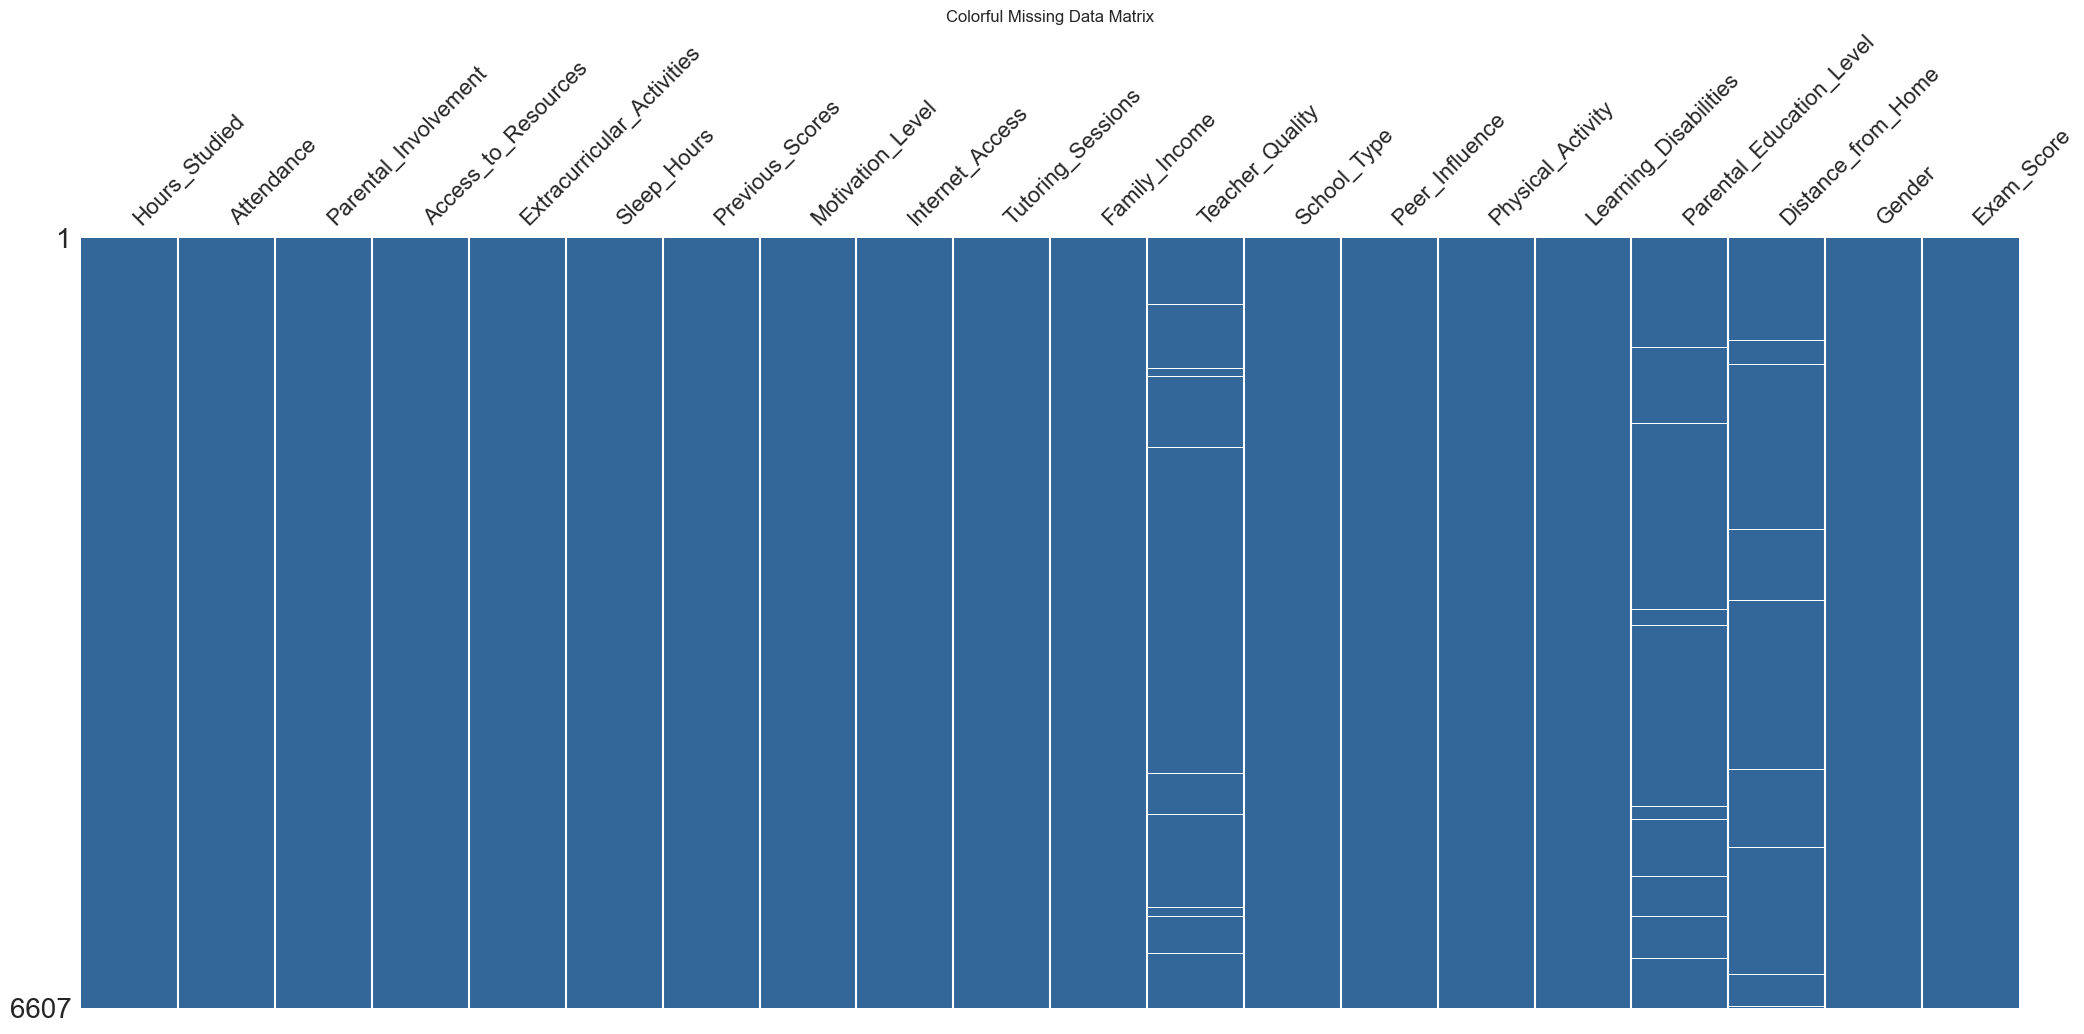

In [12]:
import missingno as msno
# Visualize the missing data with a matrix plot
# Set a colorful background and style
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")  # Set a seaborn style for the grid

# Colorful matrix plot for missing values
msno.matrix(df, sparkline=False, color=(0.2, 0.4, 0.6))  # Custom RGB color for the bars
plt.gca().set_facecolor((0.9, 0.9, 0.9))  # Light gray background
plt.title("Colorful Missing Data Matrix")
plt.show()

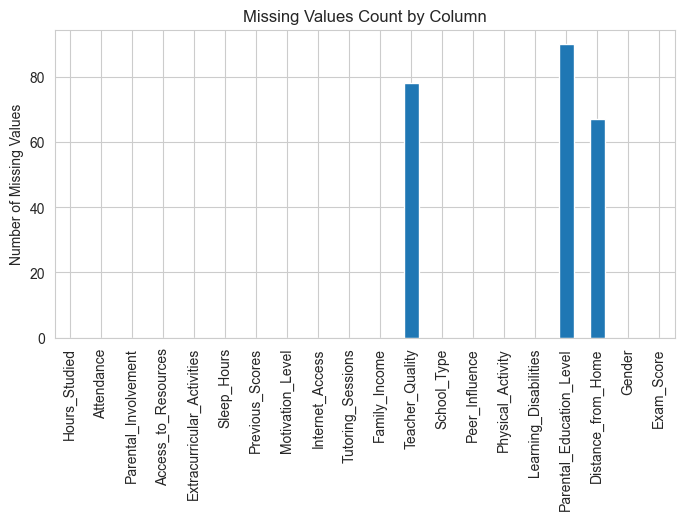

In [13]:
# Count missing values per column
missing_data = df.isnull().sum()

# Plot bar chart of missing values
missing_data.plot(kind='bar', figsize=(8, 4))
plt.title("Missing Values Count by Column")
plt.ylabel("Number of Missing Values")
plt.show()


### Taking care of the missing data

#### Droping columns that does not contain 90% data

In [14]:
# Iterate through each column in the DataFrame
for col in df.columns:
    # Check if the percentage of missing values in the column is greater than 90%
    if df[col].isnull().sum() / df.shape[0] * 100 > 90:
        # Drop the column from the DataFrame if the condition is met
        df = df.drop(col, axis=1)
        # Print the name of the dropped column
        print(col)

In [15]:
# again check
print(df.isnull() .sum())

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64


In [16]:
# Checking shape of the dataset
df.shape

(6607, 20)

##  Imputation

In [17]:
# 1. Separate categorical and numerical columns
numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns
categorical_cols = df.select_dtypes(include=['object']).columns

print(numerical_cols)
print(categorical_cols)

Index(['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores',
       'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score'],
      dtype='object')
Index(['Parental_Involvement', 'Access_to_Resources',
       'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access',
       'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence',
       'Learning_Disabilities', 'Parental_Education_Level',
       'Distance_from_Home', 'Gender'],
      dtype='object')


In [18]:
from sklearn.impute import SimpleImputer

# 2. Imputation for numerical data (using mean)
num_imputer = SimpleImputer(strategy='mean')
df[numerical_cols] = num_imputer.fit_transform(df[numerical_cols])

# 3. Imputation for categorical data (using most frequent)
cat_imputer = SimpleImputer(strategy='most_frequent')
df[categorical_cols] = cat_imputer.fit_transform(df[categorical_cols])



In [19]:
print(df.isnull() .sum())

Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64


### Checking the duplicate rows

In [20]:
# Calculate the number of duplicate rows in the DataFrame.
# This helps to identify and understand the extent of redundancy in the data.
# Removing duplicates is crucial to ensure the integrity and accuracy of our analysis.
# The sum() function will return the total count of duplicate rows.
df.duplicated().sum()

np.int64(0)

In [21]:
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23.0,84.0,Low,High,No,7.0,73.0,Low,Yes,0.0,Low,Medium,Public,Positive,3.0,No,High School,Near,Male,67.0
1,19.0,64.0,Low,Medium,No,8.0,59.0,Low,Yes,2.0,Medium,Medium,Public,Negative,4.0,No,College,Moderate,Female,61.0
2,24.0,98.0,Medium,Medium,Yes,7.0,91.0,Medium,Yes,2.0,Medium,Medium,Public,Neutral,4.0,No,Postgraduate,Near,Male,74.0
3,29.0,89.0,Low,Medium,Yes,8.0,98.0,Medium,Yes,1.0,Medium,Medium,Public,Negative,4.0,No,High School,Moderate,Male,71.0
4,19.0,92.0,Medium,Medium,Yes,6.0,65.0,Medium,Yes,3.0,Medium,High,Public,Neutral,4.0,No,College,Near,Female,70.0


<a class='anchor' id='EDA'></a>[↑](#top)

# <div style="background-color: #FF5733; font-family: 'Gill Sans', sans-serif; font-size: 36px; color: #ffffff; text-align: center; border-radius: 20px; padding: 20px; border: 2px solid #ffffff; box-shadow: 0 4px 10px rgba(0, 0, 0, 0.2);"><b>  4. EDA </b></div>


In [22]:
df_categorical_cols =df[categorical_cols]
df_numerical_cols =df[numerical_cols]
print(df_categorical_cols)
print(df_numerical_cols)


     Parental_Involvement Access_to_Resources Extracurricular_Activities  \
0                     Low                High                         No   
1                     Low              Medium                         No   
2                  Medium              Medium                        Yes   
3                     Low              Medium                        Yes   
4                  Medium              Medium                        Yes   
...                   ...                 ...                        ...   
6602                 High              Medium                         No   
6603                 High              Medium                         No   
6604               Medium                 Low                        Yes   
6605                 High                High                        Yes   
6606               Medium                 Low                        Yes   

     Motivation_Level Internet_Access Family_Income Teacher_Quality  \
0               

### Distribution of parental involvement

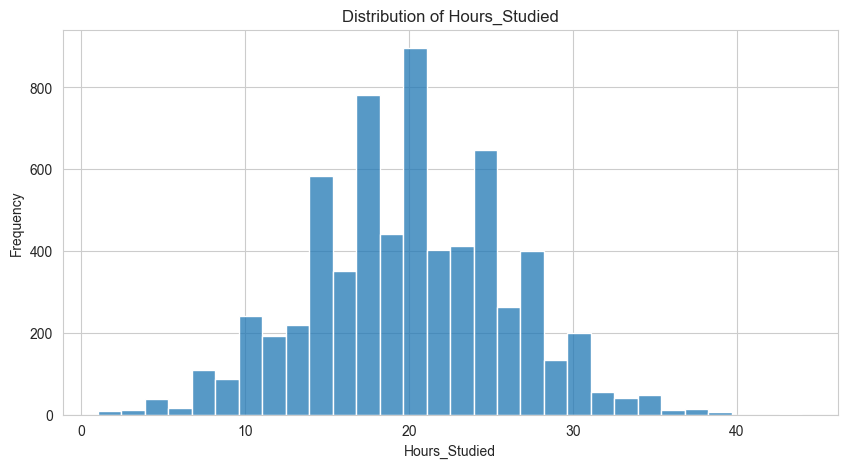

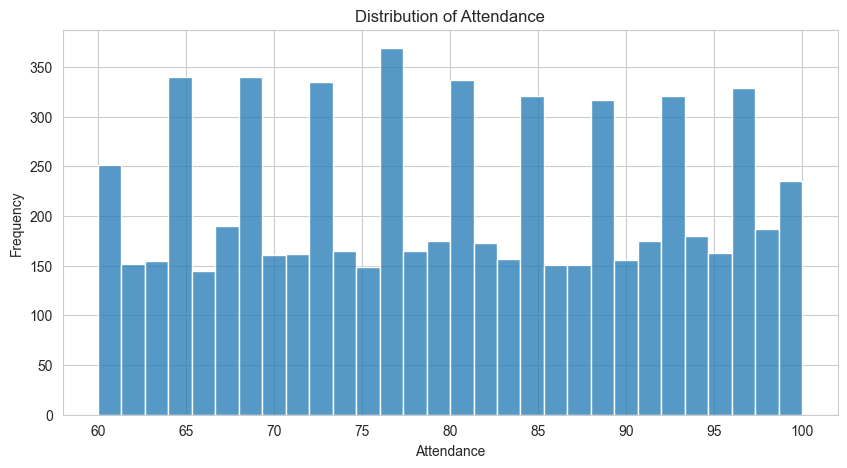

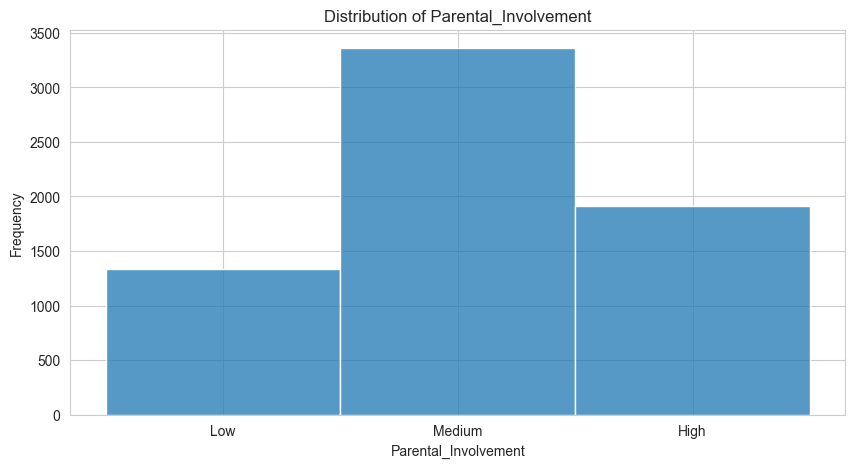

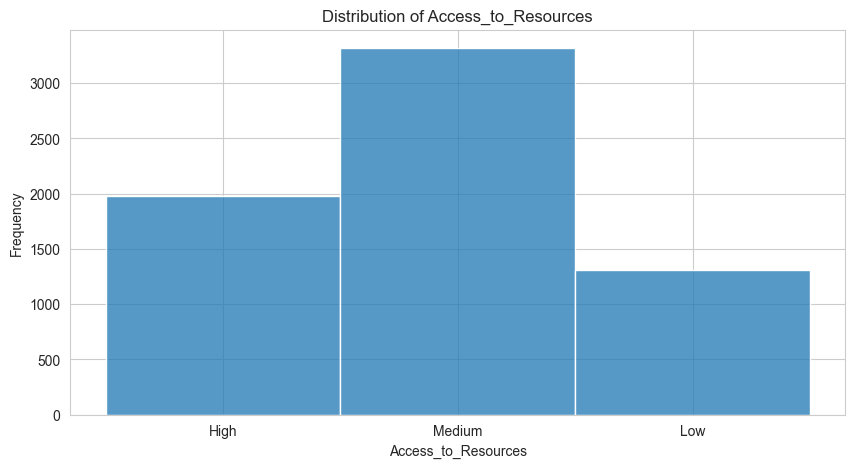

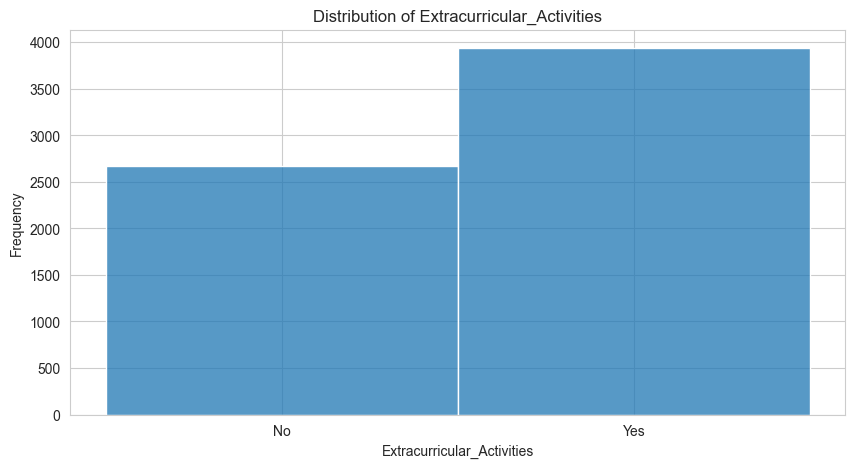

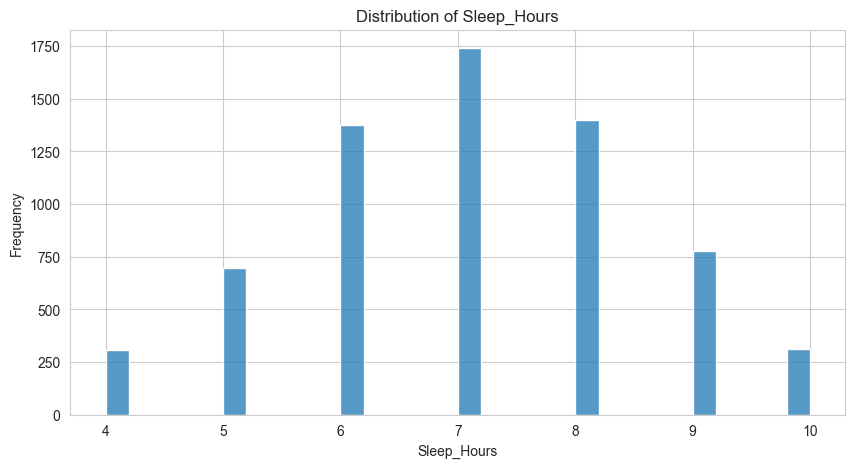

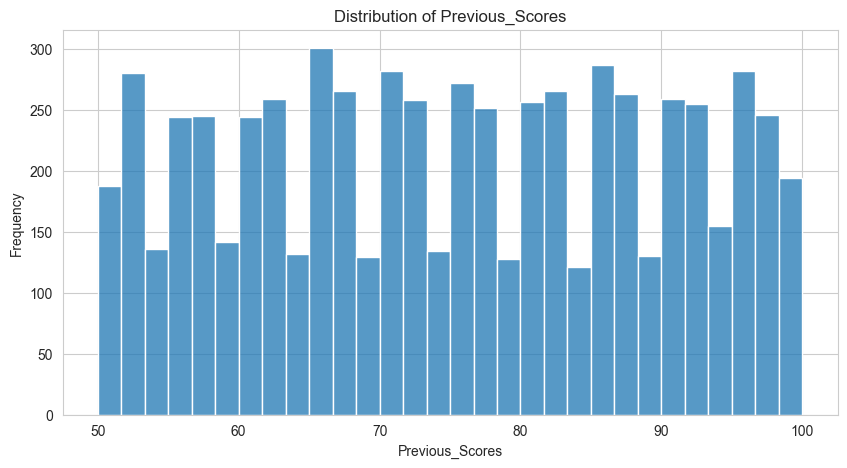

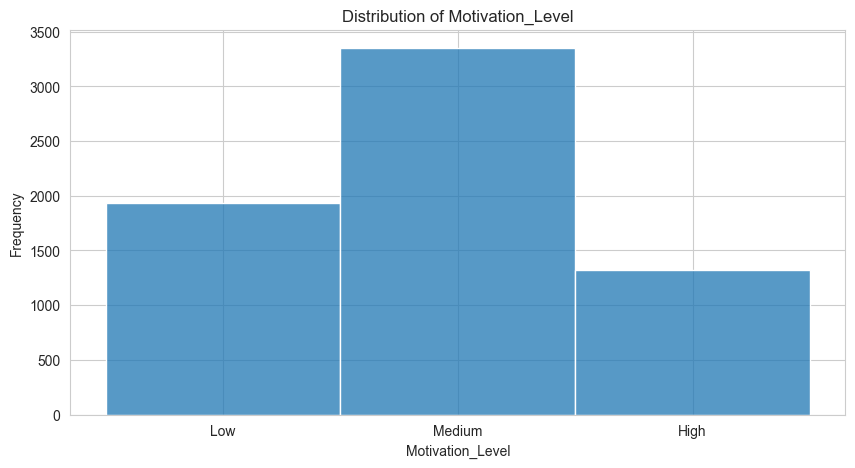

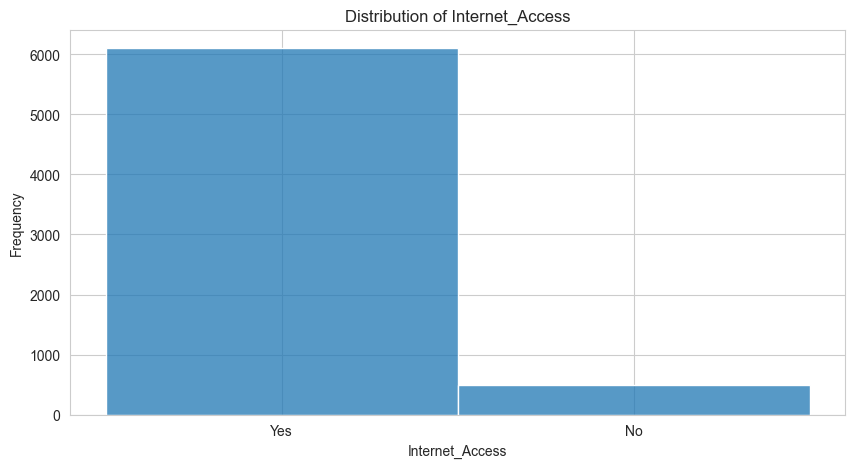

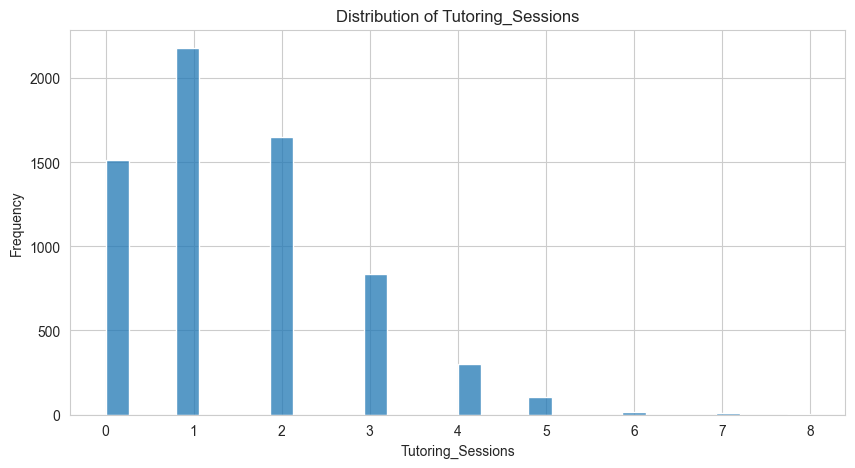

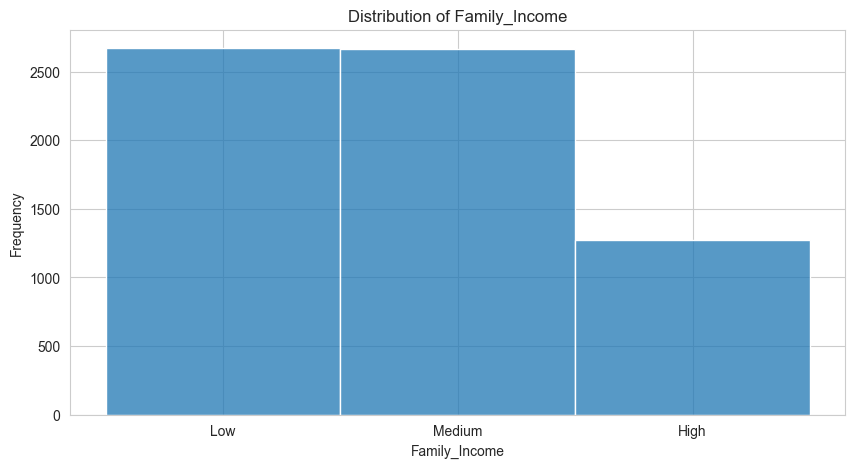

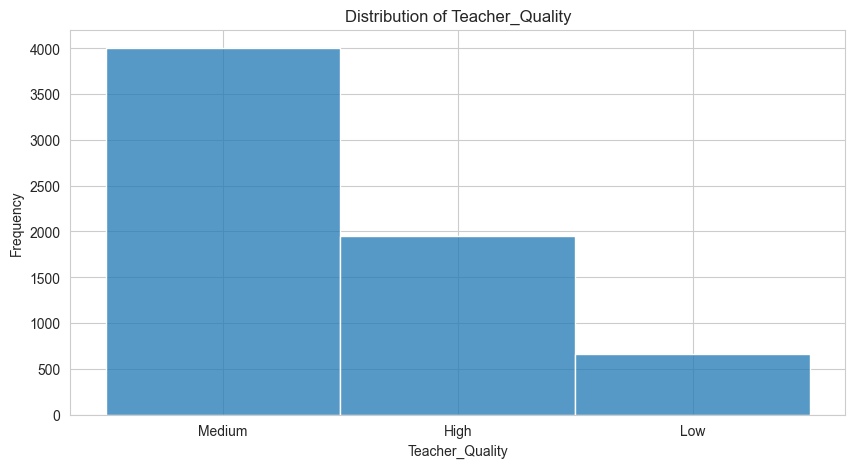

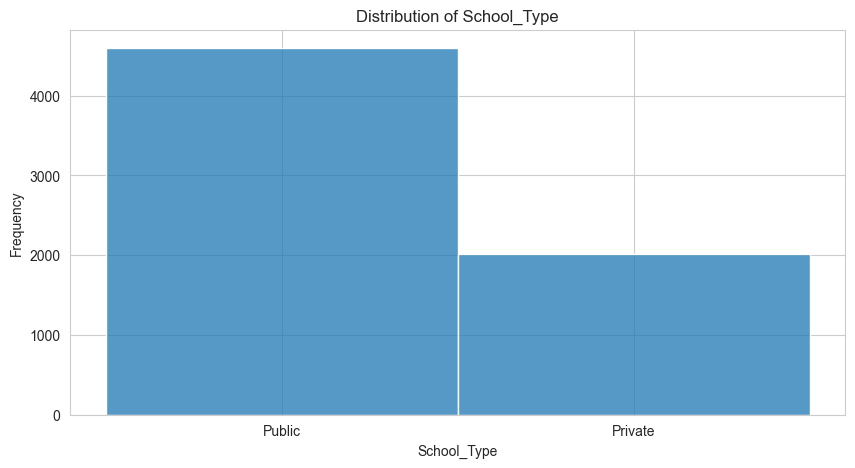

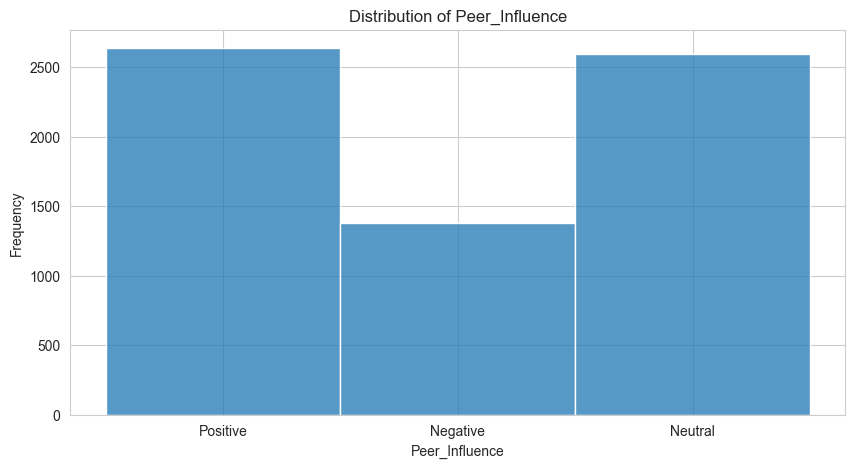

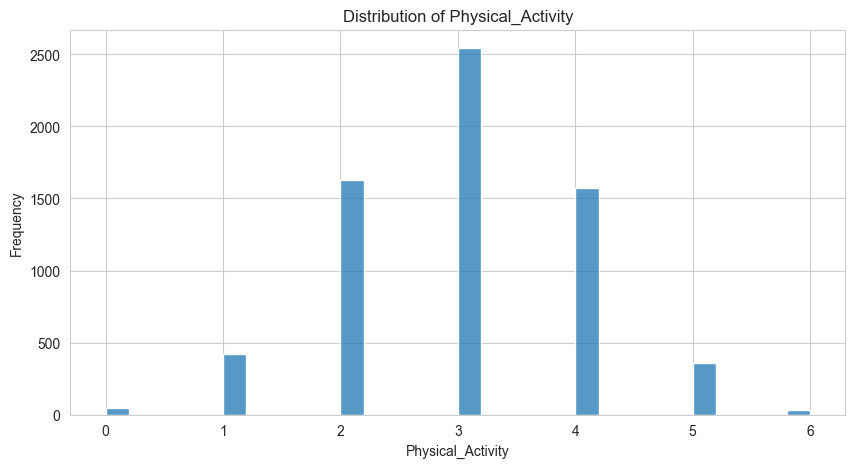

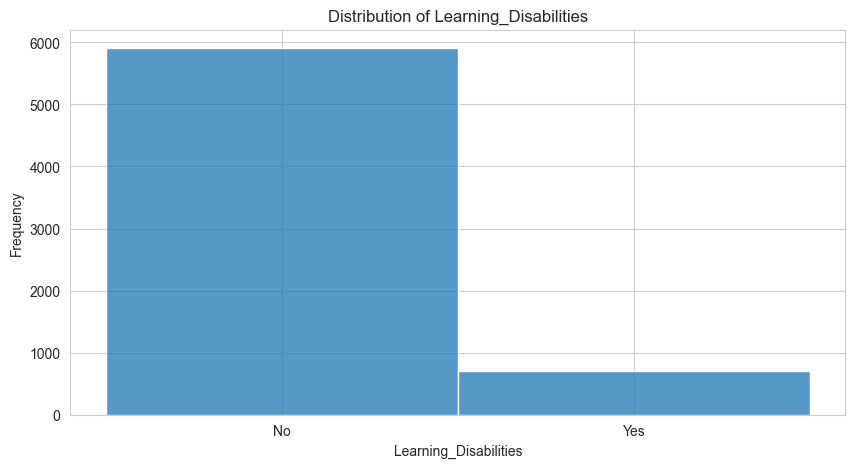

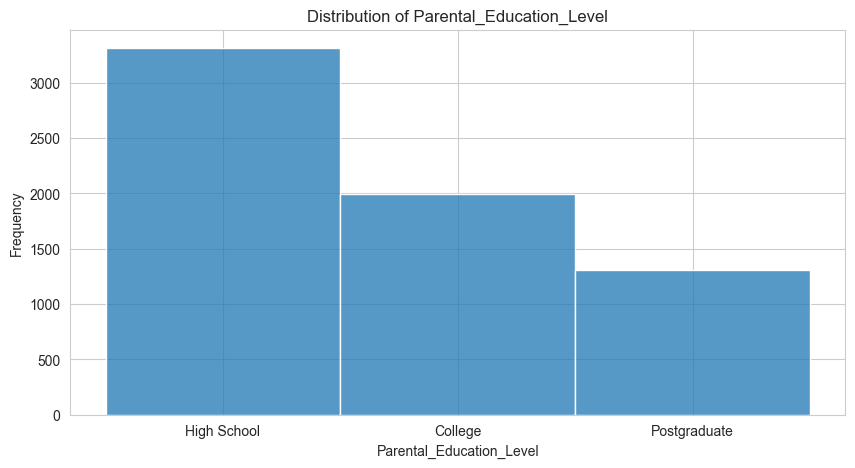

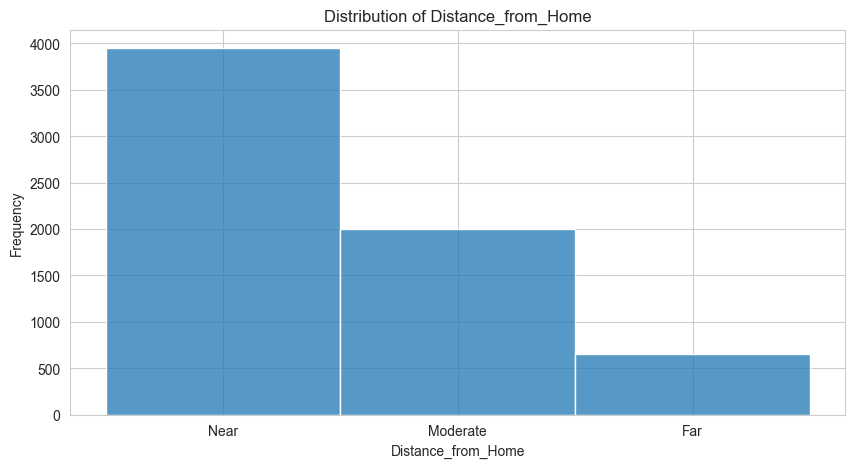

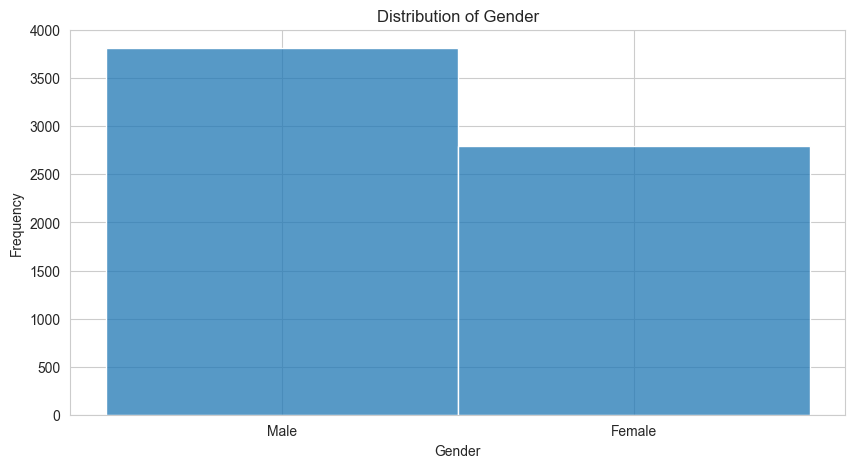

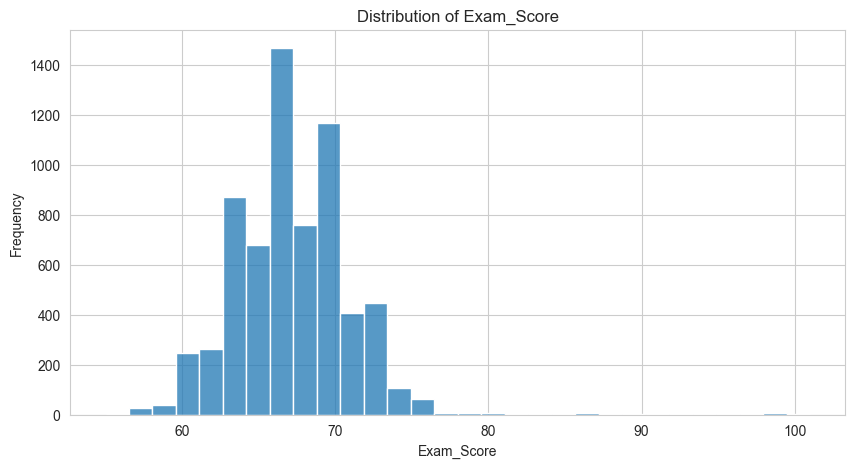

In [23]:
for column in df.columns:
    plt.figure(figsize=(10, 5))
    sns.histplot(df[column], bins=30)
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.show()

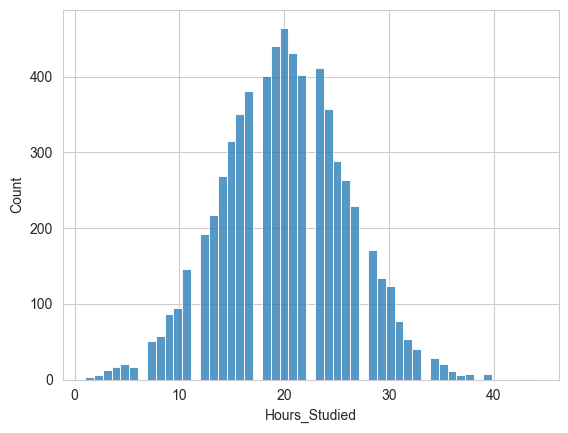

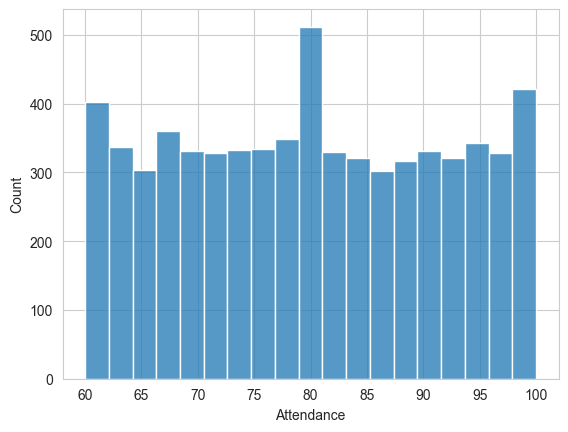

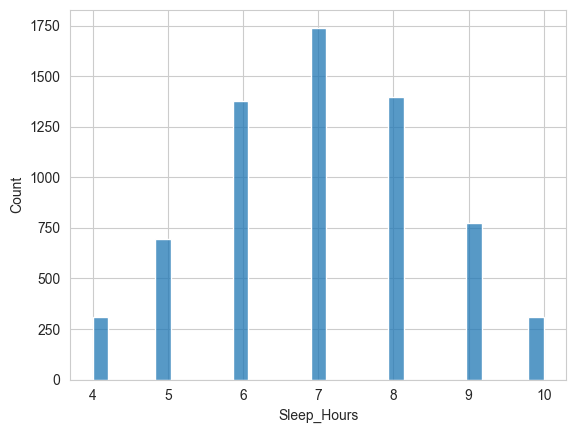

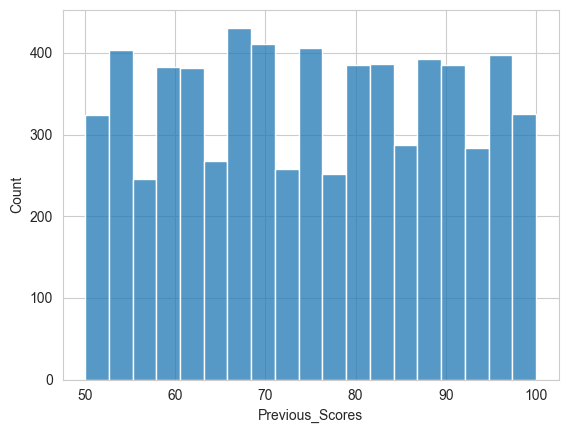

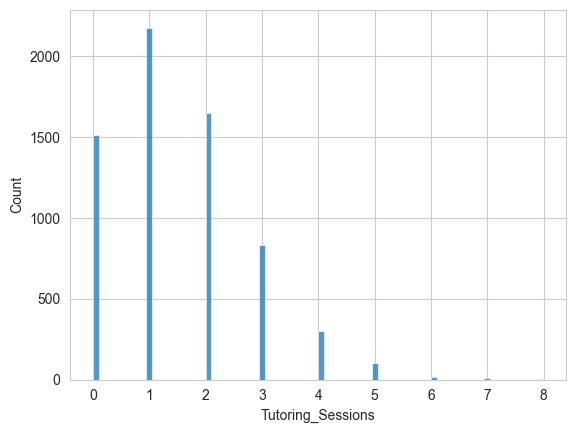

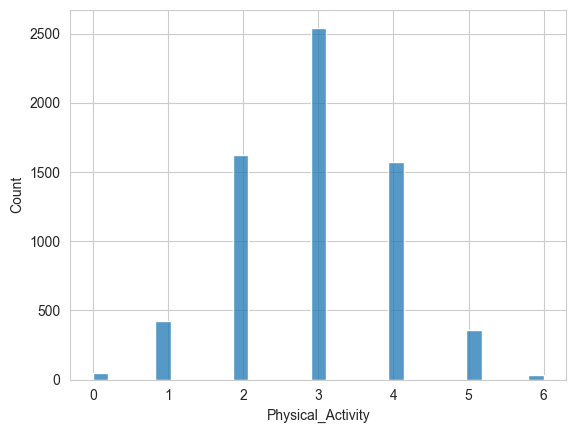

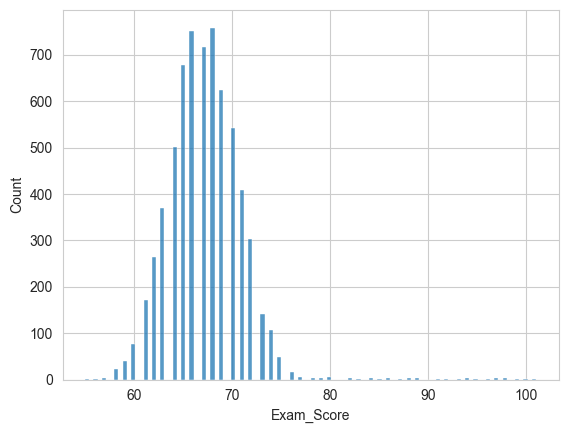

In [24]:
#show Histogram for numerical data.
for col_type in df.select_dtypes(include = "number").columns:
    sns.histplot(data = df, x = col_type)
    plt.show()



In [25]:
unique_values = df_categorical_cols.apply(lambda x: x.unique())
print(unique_values)

Parental_Involvement                           [Low, Medium, High]
Access_to_Resources                            [High, Medium, Low]
Extracurricular_Activities                               [No, Yes]
Motivation_Level                               [Low, Medium, High]
Internet_Access                                          [Yes, No]
Family_Income                                  [Low, Medium, High]
Teacher_Quality                                [Medium, High, Low]
School_Type                                      [Public, Private]
Peer_Influence                       [Positive, Negative, Neutral]
Learning_Disabilities                                    [No, Yes]
Parental_Education_Level      [High School, College, Postgraduate]
Distance_from_Home                           [Near, Moderate, Far]
Gender                                              [Male, Female]
dtype: object


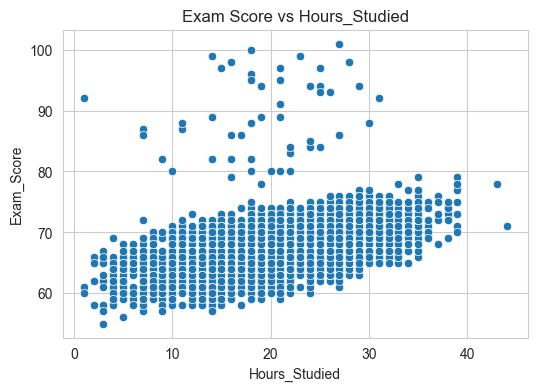

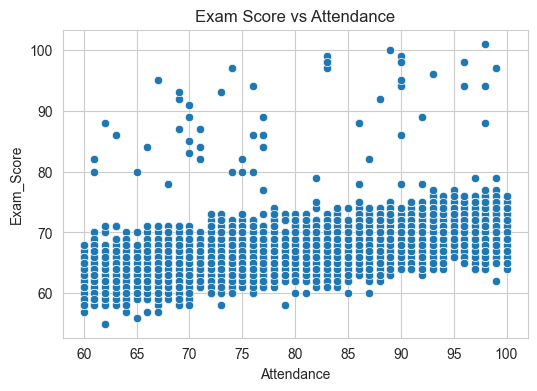

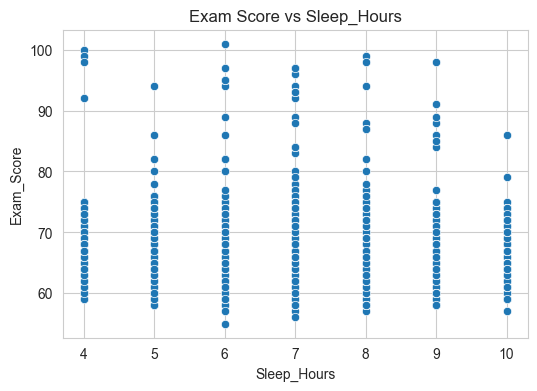

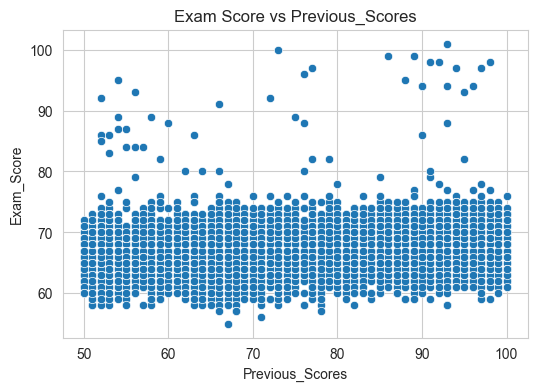

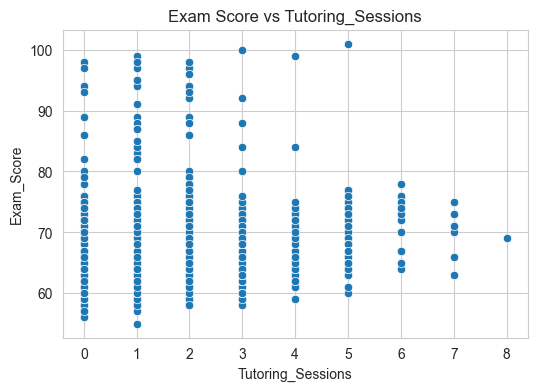

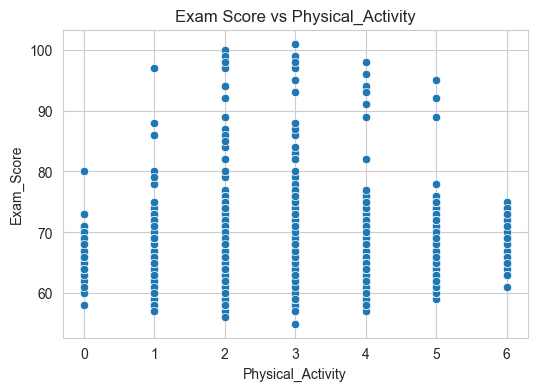

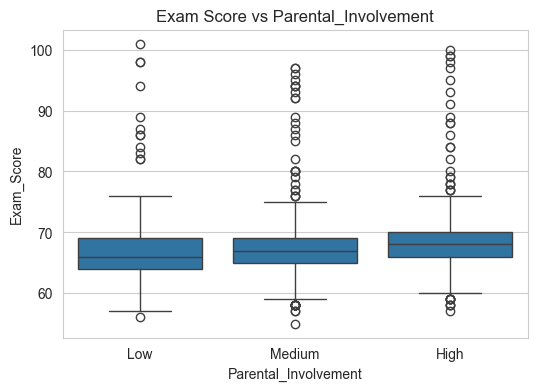

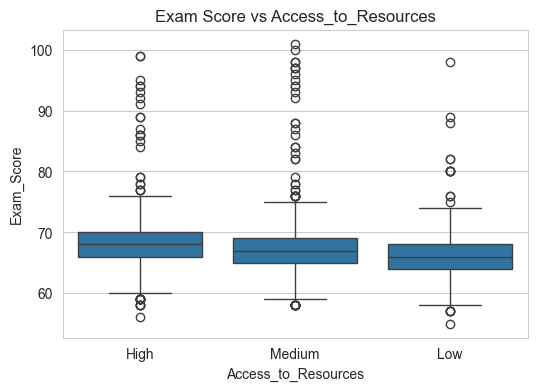

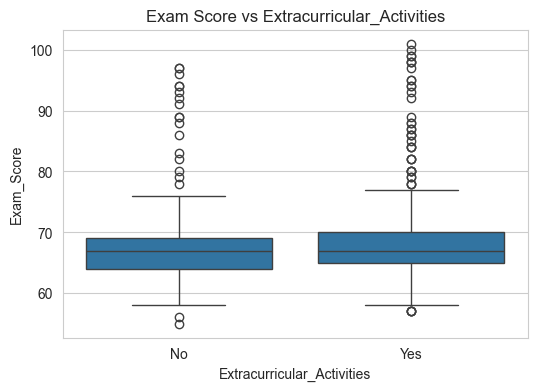

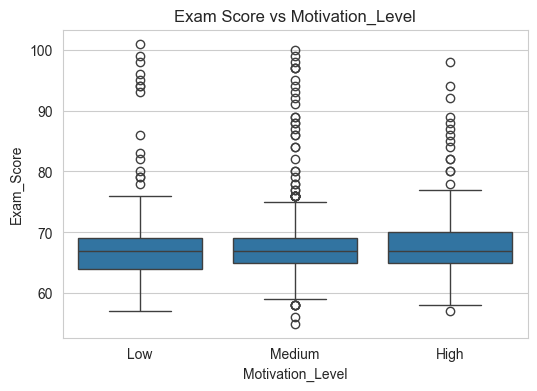

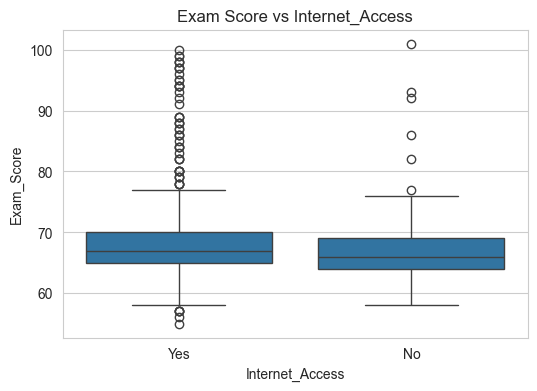

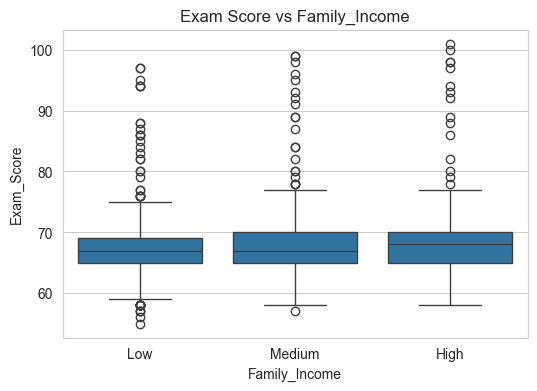

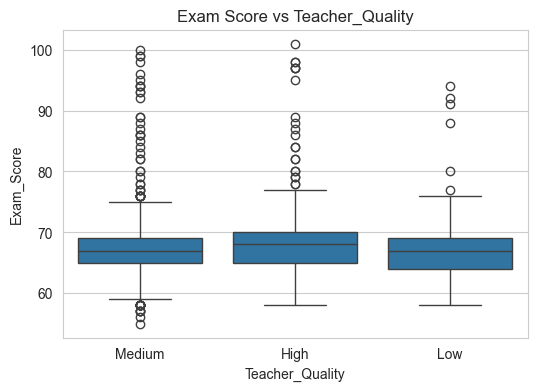

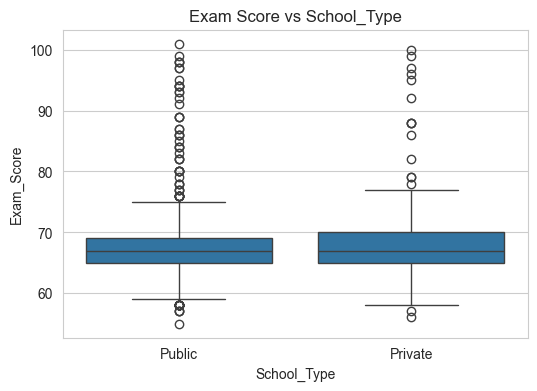

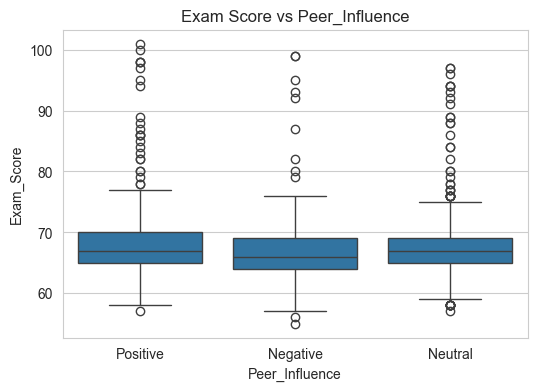

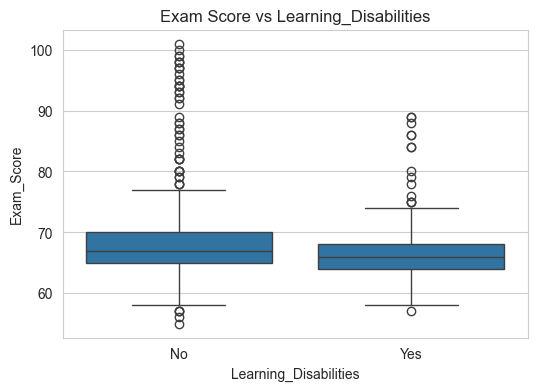

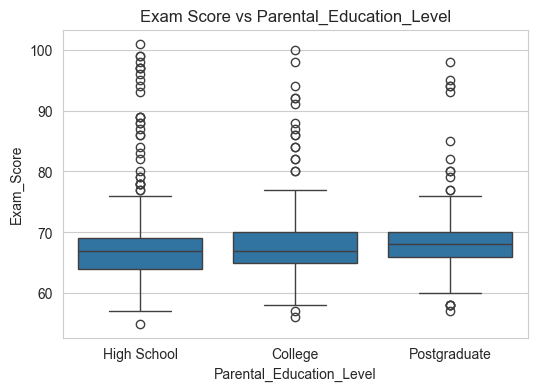

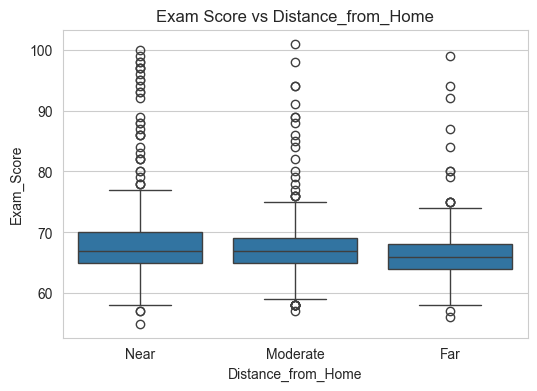

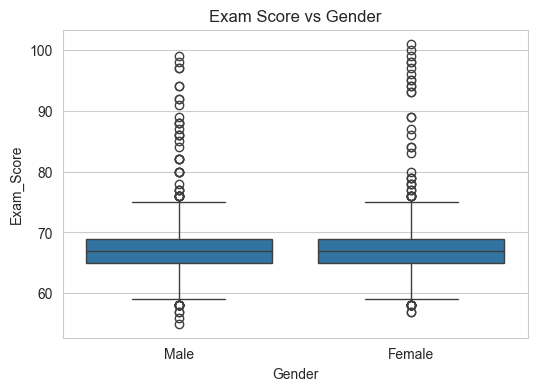

In [26]:
def plot_exam_score_vs_others(df, exam_col):
    continuous_vars = df.select_dtypes(include=['int64', 'float64']).columns.drop(exam_col)
    categorical_vars = df.select_dtypes(include=['object', 'category']).columns

    for var in continuous_vars:
        plt.figure(figsize=(6, 4))
        sns.scatterplot(x=df[var], y=df[exam_col])
        plt.title(f'Exam Score vs {var}')
        plt.show()

    for var in categorical_vars:
        plt.figure(figsize=(6, 4))
        sns.boxplot(x=df[var], y=df[exam_col])
        plt.title(f'Exam Score vs {var}')
        plt.show()

# Call the function to plot Exam_Score vs other columns
plot_exam_score_vs_others(df, 'Exam_Score')

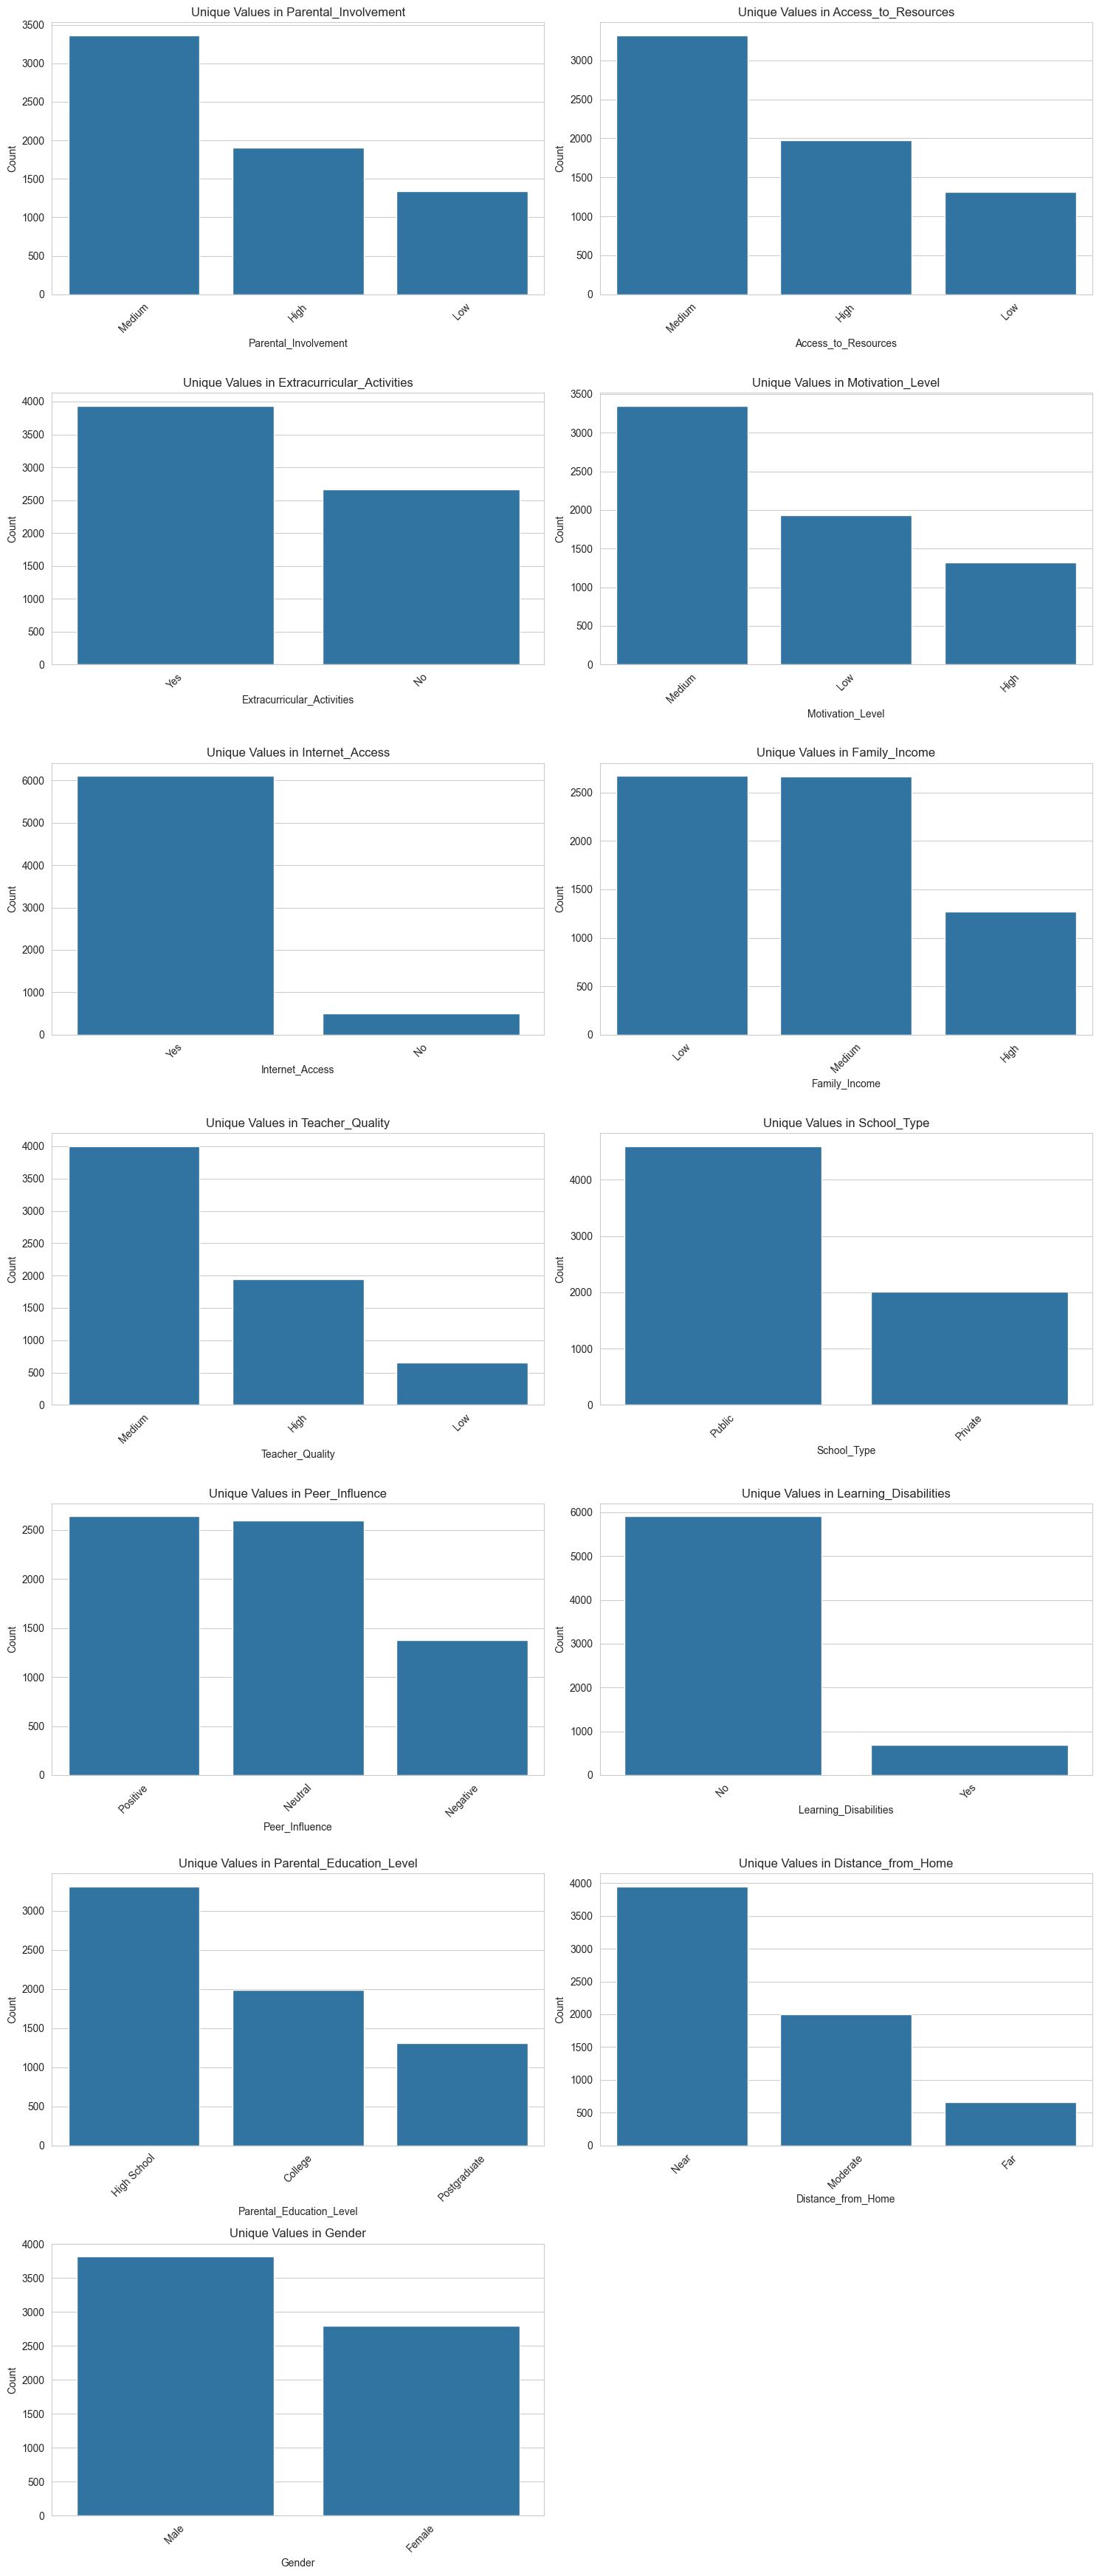

In [27]:
# Create a figure to hold the plots
num_columns = len(df_categorical_cols.columns)
plt.figure(figsize=(15, 5 * (num_columns // 2 + num_columns % 2)))  # Dynamic height based on number of columns

# Loop through each column and plot unique values
for i, column in enumerate(df_categorical_cols.columns):
    plt.subplot((num_columns // 2 + num_columns % 2), 2, i + 1)  # Create subplots
    unique_values = df_categorical_cols[column].value_counts()  # Count unique values
    sns.barplot(x=unique_values.index, y=unique_values.values)  # Create a bar plot
    plt.title(f'Unique Values in {column}')
    plt.xlabel(column)
    plt.ylabel('Count')
    plt.xticks(rotation=45)  # Rotate x labels for better readability

# Adjust layout
plt.tight_layout()
plt.show()

 ## Regression Line for Continuous Variables

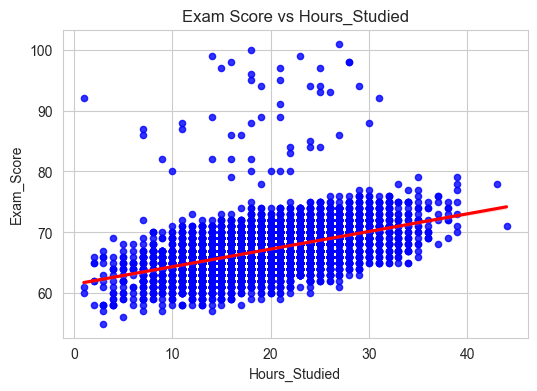

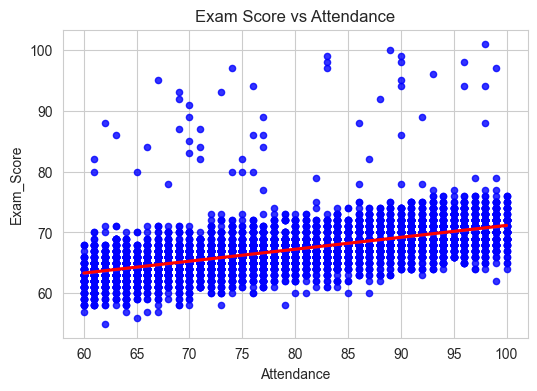

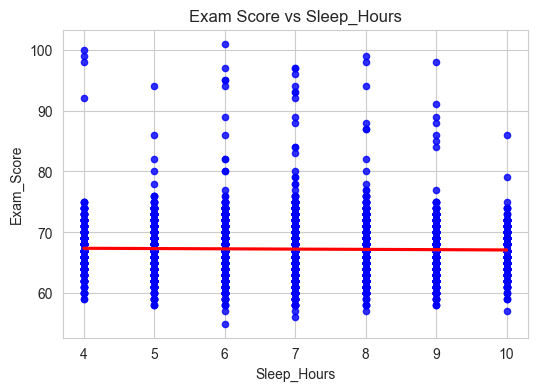

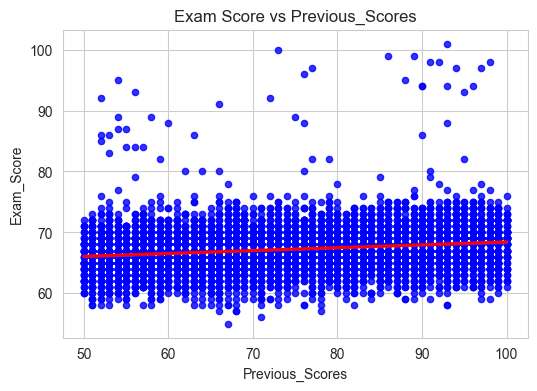

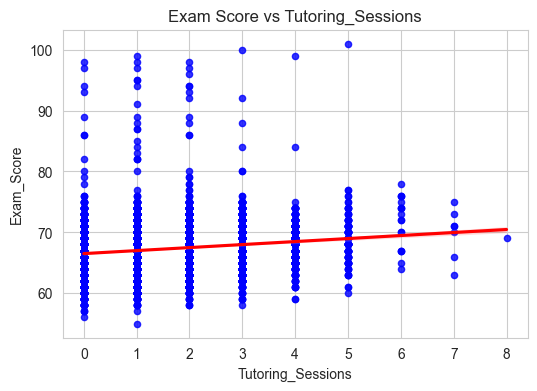

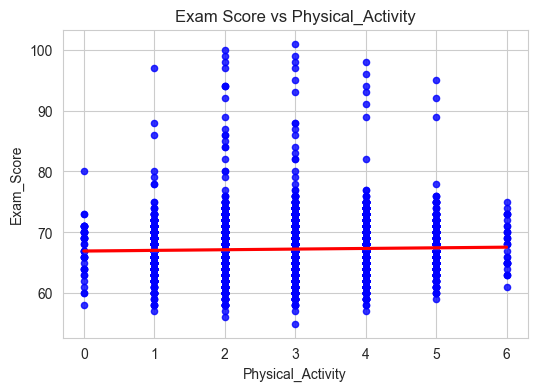

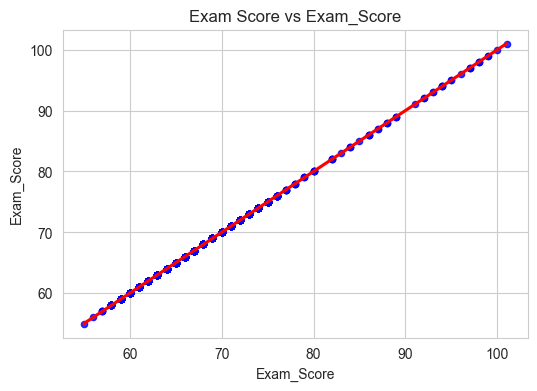

In [28]:

for var in numerical_cols:
    plt.figure(figsize=(6, 4))
    sns.regplot(x=var, y='Exam_Score', data=df_numerical_cols,line_kws={'color': 'red'},scatter_kws={'color': 'blue', 's': 20})
    plt.title(f'Exam Score vs {var}')
    plt.show()

 ### Box Plots for Categorical Variables

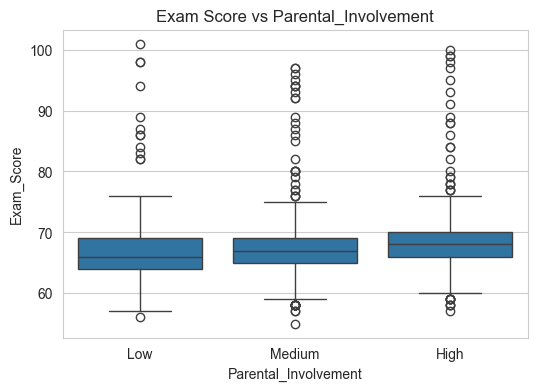

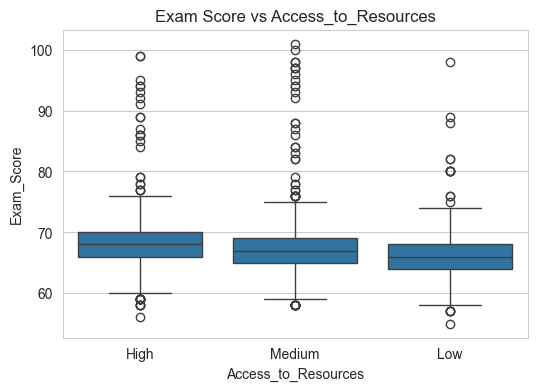

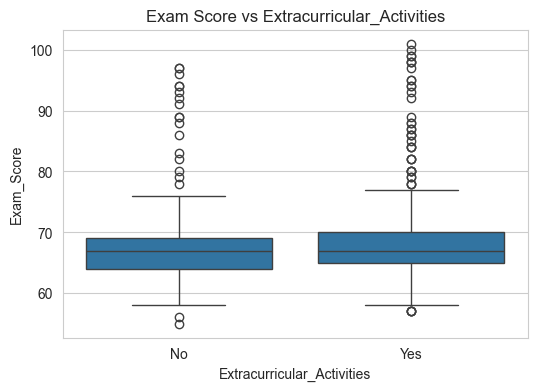

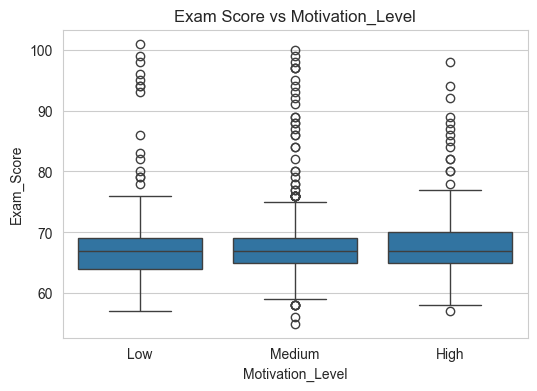

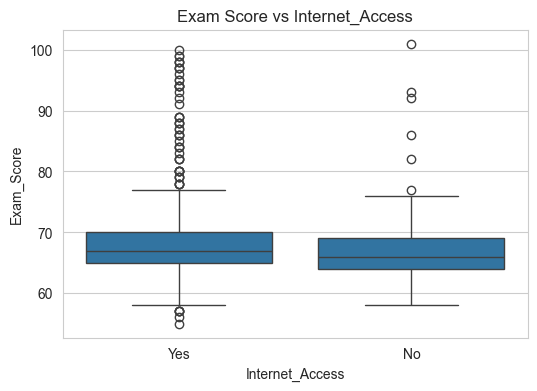

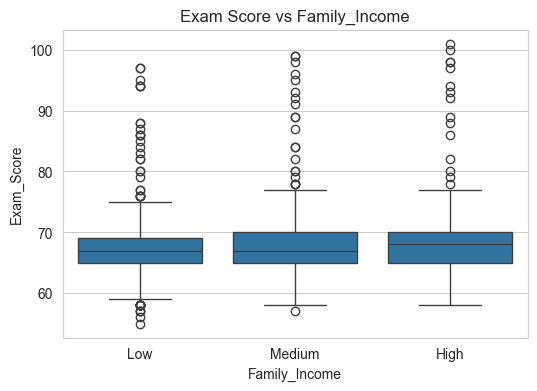

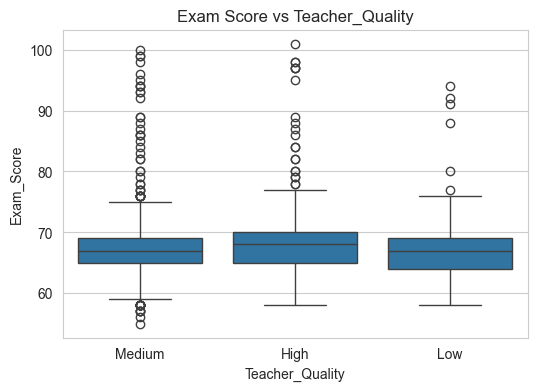

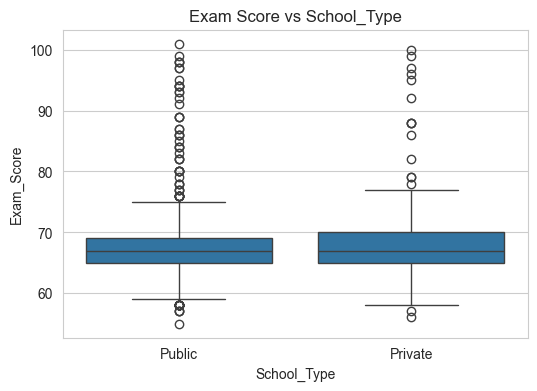

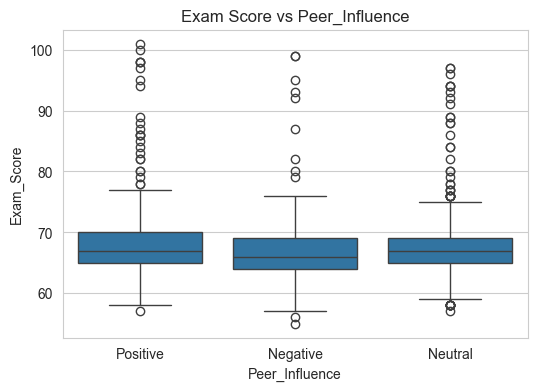

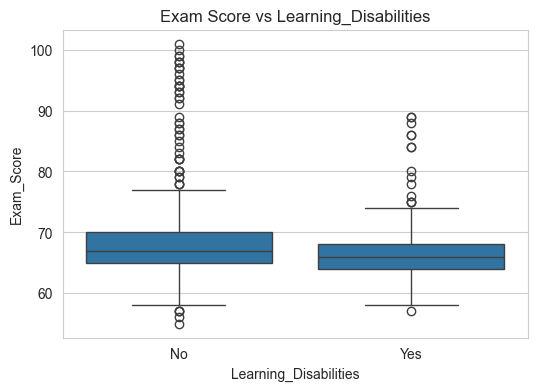

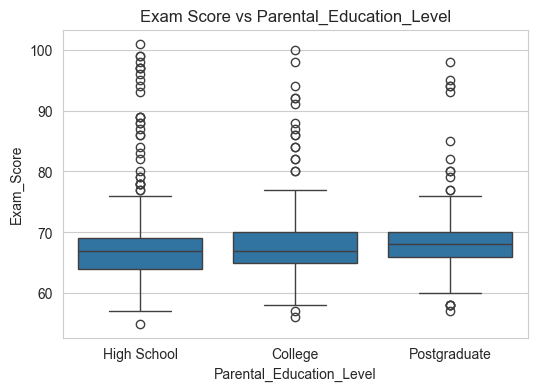

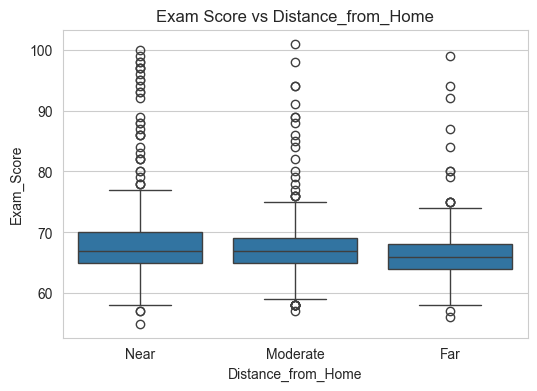

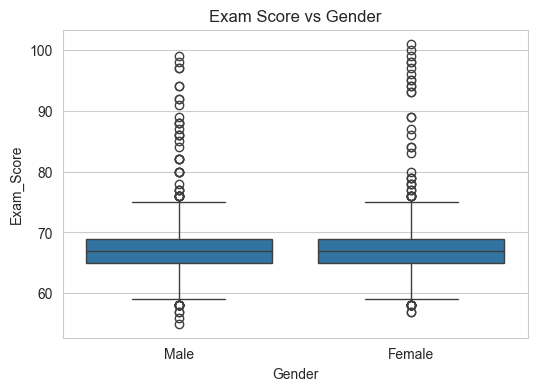

In [29]:
for var in categorical_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=var, y='Exam_Score', data=df)
    plt.title(f'Exam Score vs {var}')
    plt.show()

C:\Users\ayoub\AppData\Local\Temp\ipykernel_24116\3213427860.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Gender', y='Exam_Score', data=df, palette='Set2')


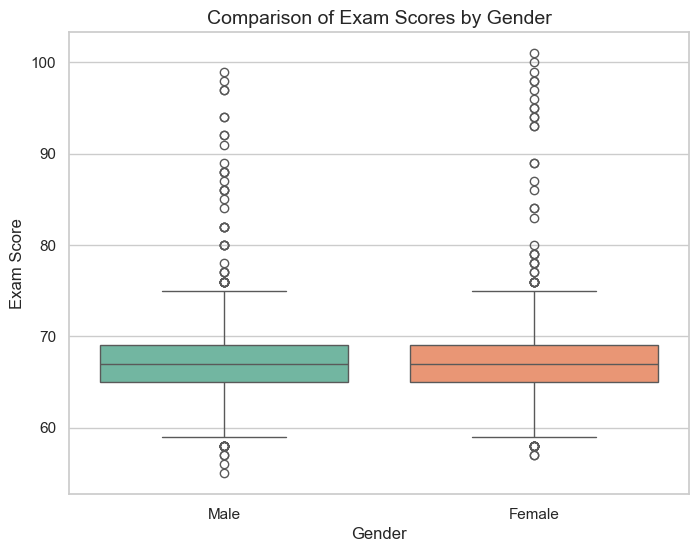

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the plot style
sns.set(style="whitegrid")

# Create a boxplot to compare Exam_Score by Gender
plt.figure(figsize=(8, 6))
sns.boxplot(x='Gender', y='Exam_Score', data=df, palette='Set2')

# Add title and labels
plt.title('Comparison of Exam Scores by Gender', fontsize=14)
plt.xlabel('Gender', fontsize=12)
plt.ylabel('Exam Score', fontsize=12)

# Display the plot
plt.show()


C:\Users\ayoub\AppData\Local\Temp\ipykernel_24116\1111342792.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df[(df.Teacher_Quality == 'Low')]["Exam_Score"],color='c',ax=ax)
C:\Users\ayoub\AppData\Local\Temp\ipykernel_24116\1111342792.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df[(d

Text(0.5, 1.0, 'Distribution of charges for Low')

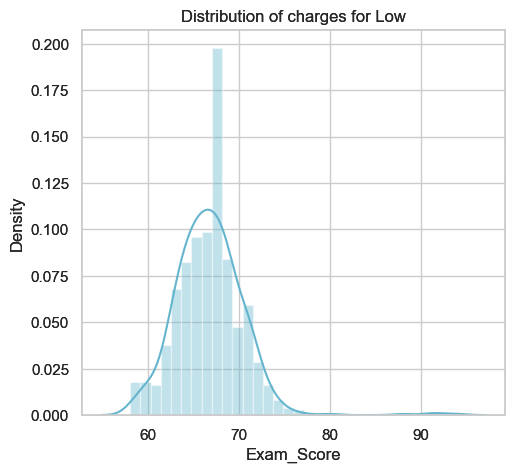

In [31]:
f= plt.figure(figsize=(12,5))

ax=f.add_subplot(121)
sns.distplot(df[(df.Teacher_Quality == 'Low')]["Exam_Score"],color='c',ax=ax)
ax.set_title('Distribution of charges for Low')


ax=f.add_subplot(121)
sns.distplot(df[(df.Teacher_Quality == 'Low')]["Exam_Score"],color='c',ax=ax)
ax.set_title('Distribution of charges for Low')

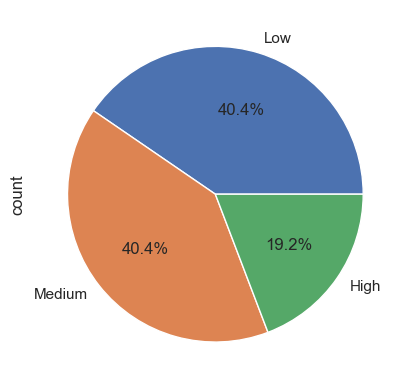

In [32]:

# Class distribution
df['Family_Income'].value_counts().plot.pie(autopct='%1.1f%%')
plt.show()

<a  class='anchor'  id="Encoding"></a>[↑](#top)

# <div style="background-color: #FF5733; font-family: 'Gill Sans', sans-serif; font-size: 36px; color: #ffffff; text-align: center; border-radius: 20px; padding: 20px; border: 2px solid #ffffff; box-shadow: 0 4px 10px rgba(0, 0, 0, 0.2);"><b>  5. Label Encoding </b></div>



In [33]:
print(numerical_cols)


Index(['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores',
       'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score'],
      dtype='object')


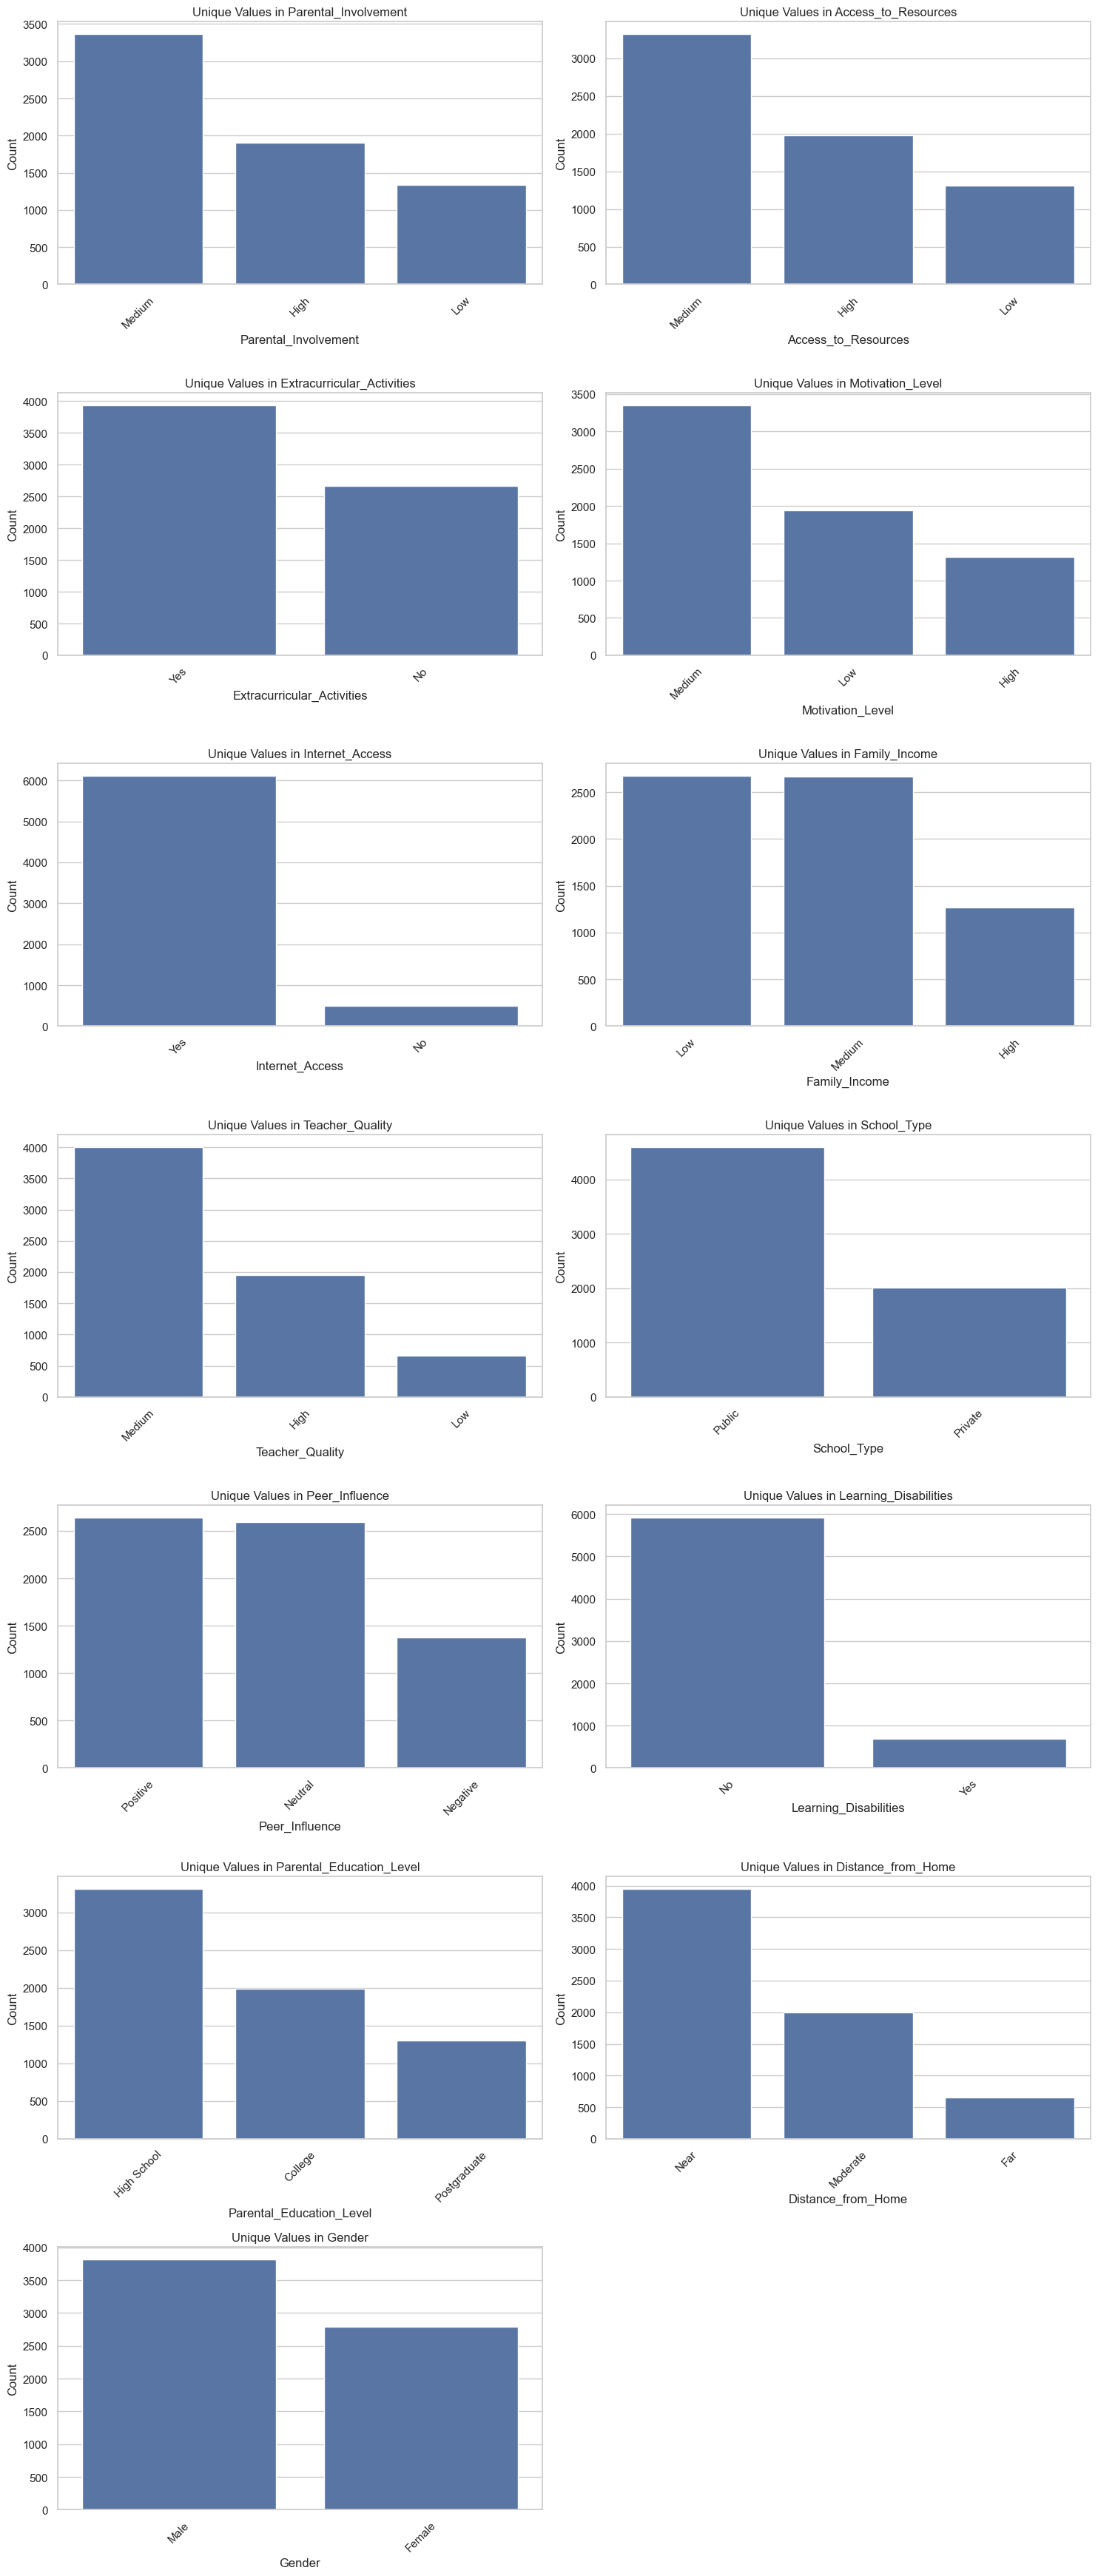

In [34]:
# Create a figure to hold the plots
num_columns = len(df_categorical_cols.columns)
plt.figure(figsize=(15, 5 * (num_columns // 2 + num_columns % 2)))  # Dynamic height based on number of columns

# Loop through each column and plot unique values
for i, column in enumerate(df_categorical_cols.columns):
    plt.subplot((num_columns // 2 + num_columns % 2), 2, i + 1)  # Create subplots
    unique_values = df_categorical_cols[column].value_counts()  # Count unique values
    sns.barplot(x=unique_values.index, y=unique_values.values)  # Create a bar plot
    plt.title(f'Unique Values in {column}')
    plt.xlabel(column)
    plt.ylabel('Count')
    plt.xticks(rotation=45)  # Rotate x labels for better readability

# Adjust layout
plt.tight_layout()
plt.show()

In [35]:
print(categorical_cols)


Index(['Parental_Involvement', 'Access_to_Resources',
       'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access',
       'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence',
       'Learning_Disabilities', 'Parental_Education_Level',
       'Distance_from_Home', 'Gender'],
      dtype='object')


In [36]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

# Loop through the columns and apply LabelEncoder
for column in categorical_cols:
    df[f'{column}_encoded'] = label_encoder.fit_transform(df[column])

In [37]:
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,...,Motivation_Level_encoded,Internet_Access_encoded,Family_Income_encoded,Teacher_Quality_encoded,School_Type_encoded,Peer_Influence_encoded,Learning_Disabilities_encoded,Parental_Education_Level_encoded,Distance_from_Home_encoded,Gender_encoded
0,23.0,84.0,Low,High,No,7.0,73.0,Low,Yes,0.0,...,1,1,1,2,1,2,0,1,2,1
1,19.0,64.0,Low,Medium,No,8.0,59.0,Low,Yes,2.0,...,1,1,2,2,1,0,0,0,1,0
2,24.0,98.0,Medium,Medium,Yes,7.0,91.0,Medium,Yes,2.0,...,2,1,2,2,1,1,0,2,2,1
3,29.0,89.0,Low,Medium,Yes,8.0,98.0,Medium,Yes,1.0,...,2,1,2,2,1,0,0,1,1,1
4,19.0,92.0,Medium,Medium,Yes,6.0,65.0,Medium,Yes,3.0,...,2,1,2,0,1,1,0,0,2,0


## Scaler

In [38]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Initialize StandardScaler for features that are assumed to follow a normal distribution
scaler = StandardScaler()

# Apply standard scaling to 'Hours_Studied', 'Sleep_Hours', and 'Physical_Activity'
df[['Hours_Studied', 'Sleep_Hours', 'Physical_Activity']] = scaler.fit_transform(
    df[['Hours_Studied', 'Sleep_Hours', 'Physical_Activity']]
)

# Initialize MinMaxScaler for scaling features between a range (0, 1 by default)
min_max_scaler = MinMaxScaler()

# Apply min-max scaling to 'Attendance' and 'Previous_Scores'
df[['Attendance', 'Previous_Scores']] = min_max_scaler.fit_transform(
    df[['Attendance', 'Previous_Scores']]
)


In [39]:
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,...,Motivation_Level_encoded,Internet_Access_encoded,Family_Income_encoded,Teacher_Quality_encoded,School_Type_encoded,Peer_Influence_encoded,Learning_Disabilities_encoded,Parental_Education_Level_encoded,Distance_from_Home_encoded,Gender_encoded
0,0.504942,0.600,Low,High,No,-0.019796,0.46,Low,Yes,0.0,...,1,1,1,2,1,2,0,1,2,1
1,-0.162822,0.100,Low,Medium,No,0.661399,0.18,Low,Yes,2.0,...,1,1,2,2,1,0,0,0,1,0
2,0.671882,0.950,Medium,Medium,Yes,-0.019796,0.82,Medium,Yes,2.0,...,2,1,2,2,1,1,0,2,2,1
3,1.506587,0.725,Low,Medium,Yes,0.661399,0.96,Medium,Yes,1.0,...,2,1,2,2,1,0,0,1,1,1
4,-0.162822,0.800,Medium,Medium,Yes,-0.700990,0.30,Medium,Yes,3.0,...,2,1,2,0,1,1,0,0,2,0


In [40]:
df.dtypes

Hours_Studied                         float64
Attendance                            float64
Parental_Involvement                   object
Access_to_Resources                    object
Extracurricular_Activities             object
Sleep_Hours                           float64
Previous_Scores                       float64
Motivation_Level                       object
Internet_Access                        object
Tutoring_Sessions                     float64
Family_Income                          object
Teacher_Quality                        object
School_Type                            object
Peer_Influence                         object
Physical_Activity                     float64
Learning_Disabilities                  object
Parental_Education_Level               object
Distance_from_Home                     object
Gender                                 object
Exam_Score                            float64
Parental_Involvement_encoded            int64
Access_to_Resources_encoded       

<a class='anchor' id='Engineering'></a>[↑](#top)

# <div style="background-color: #FF5733; font-family: 'Gill Sans', sans-serif; font-size: 36px; color: #ffffff; text-align: center; border-radius: 20px; padding: 20px; border: 2px solid #ffffff; box-shadow: 0 4px 10px rgba(0, 0, 0, 0.2);"><b>  6. Feature Engineering </b></div>



##  Correlation Martix between columns


In [41]:
numerical_all_colslist = df.select_dtypes(include=['float64', 'int64','int32']).columns
numerical_all_cols = df[numerical_all_colslist]
numerical_all_cols.head()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score,Parental_Involvement_encoded,Access_to_Resources_encoded,Extracurricular_Activities_encoded,Motivation_Level_encoded,Internet_Access_encoded,Family_Income_encoded,Teacher_Quality_encoded,School_Type_encoded,Peer_Influence_encoded,Learning_Disabilities_encoded,Parental_Education_Level_encoded,Distance_from_Home_encoded,Gender_encoded
0,0.504942,0.600,-0.019796,0.46,0.0,0.031411,67.0,1,0,0,1,1,1,2,1,2,0,1,2,1
1,-0.162822,0.100,0.661399,0.18,2.0,1.001199,61.0,1,2,0,1,1,2,2,1,0,0,0,1,0
2,0.671882,0.950,-0.019796,0.82,2.0,1.001199,74.0,2,2,1,2,1,2,2,1,1,0,2,2,1
3,1.506587,0.725,0.661399,0.96,1.0,1.001199,71.0,1,2,1,2,1,2,2,1,0,0,1,1,1
4,-0.162822,0.800,-0.700990,0.30,3.0,1.001199,70.0,2,2,1,2,1,2,0,1,1,0,0,2,0


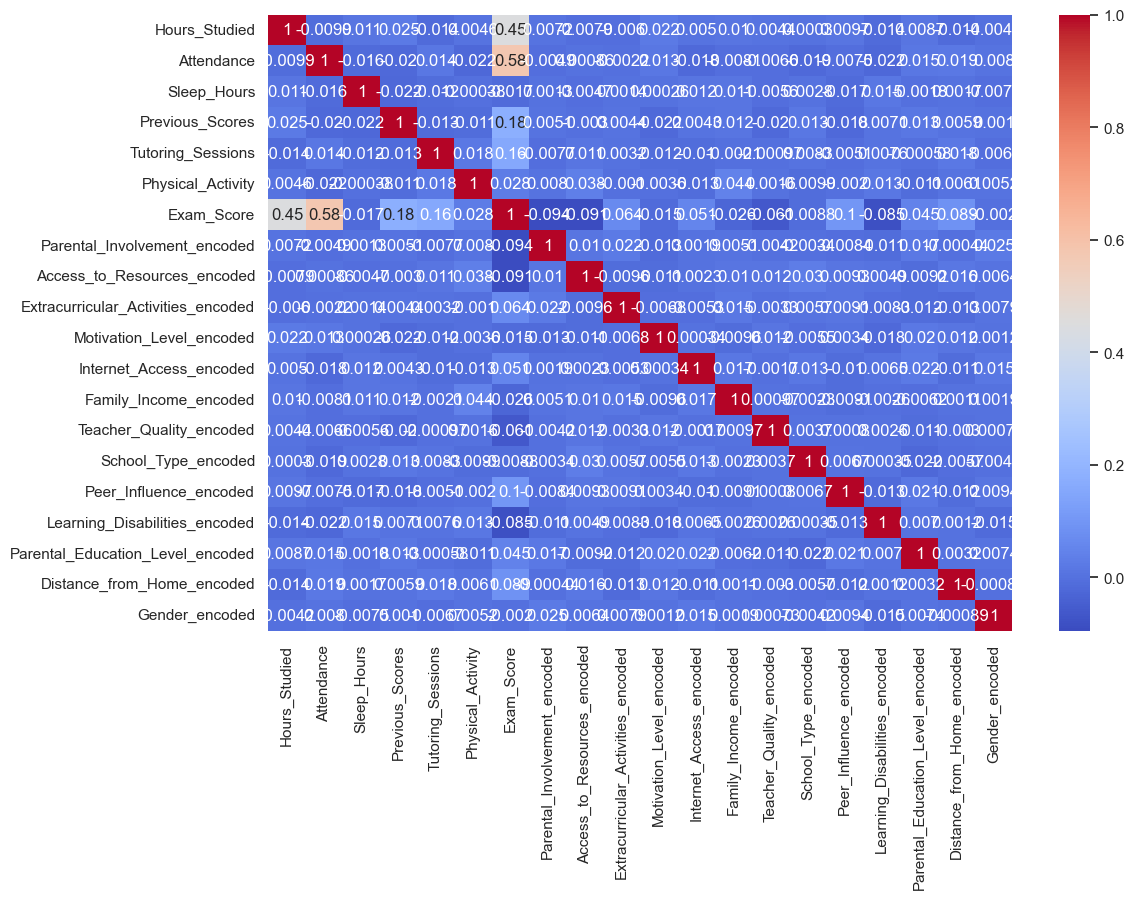

In [42]:
corr_matrix = numerical_all_cols.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.show()

In [43]:
df_numerical_all_cols = numerical_all_cols.drop(['Sleep_Hours', 'Physical_Activity', 'Internet_Access_encoded'], axis=1)
df_numerical_all_cols.head()

,Hours_Studied,Attendance,Previous_Scores,Tutoring_Sessions,Exam_Score,Parental_Involvement_encoded,Access_to_Resources_encoded,Extracurricular_Activities_encoded,Motivation_Level_encoded,Family_Income_encoded,Teacher_Quality_encoded,School_Type_encoded,Peer_Influence_encoded,Learning_Disabilities_encoded,Parental_Education_Level_encoded,Distance_from_Home_encoded,Gender_encoded
0,0.504942,0.600,0.46,0.0,67.0,1,0,0,1,1,2,1,2,0,1,2,1
1,-0.162822,0.100,0.18,2.0,61.0,1,2,0,1,2,2,1,0,0,0,1,0
2,0.671882,0.950,0.82,2.0,74.0,2,2,1,2,2,2,1,1,0,2,2,1
3,1.506587,0.725,0.96,1.0,71.0,1,2,1,2,2,2,1,0,0,1,1,1
4,-0.162822,0.800,0.30,3.0,70.0,2,2,1,2,2,0,1,1,0,0,2,0


In [44]:
numerical_all_cols.shape

(6607, 20)

In [45]:
df_numerical_all_cols.shape

(6607, 17)

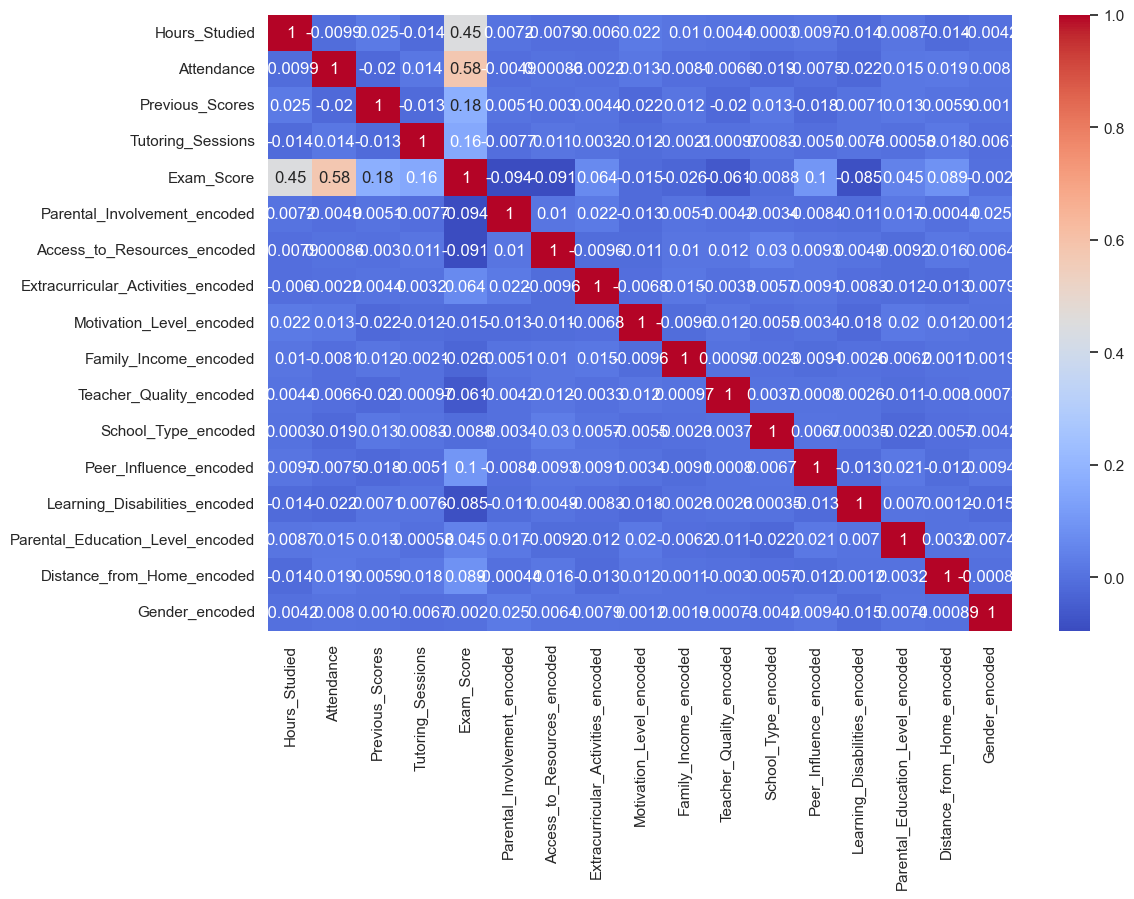

In [46]:
corr_matrix = df_numerical_all_cols.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.show()

In [47]:
df_numerical_all_cols_Gender = numerical_all_cols.drop(['Gender_encoded', 'Family_Income_encoded','Learning_Disabilities_encoded'], axis=1)
df_numerical_all_cols_Gender.head()


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score,Parental_Involvement_encoded,Access_to_Resources_encoded,Extracurricular_Activities_encoded,Motivation_Level_encoded,Internet_Access_encoded,Teacher_Quality_encoded,School_Type_encoded,Peer_Influence_encoded,Parental_Education_Level_encoded,Distance_from_Home_encoded
0,0.504942,0.600,-0.019796,0.46,0.0,0.031411,67.0,1,0,0,1,1,2,1,2,1,2
1,-0.162822,0.100,0.661399,0.18,2.0,1.001199,61.0,1,2,0,1,1,2,1,0,0,1
2,0.671882,0.950,-0.019796,0.82,2.0,1.001199,74.0,2,2,1,2,1,2,1,1,2,2
3,1.506587,0.725,0.661399,0.96,1.0,1.001199,71.0,1,2,1,2,1,2,1,0,1,1
4,-0.162822,0.800,-0.700990,0.30,3.0,1.001199,70.0,2,2,1,2,1,0,1,1,0,2


In [48]:
final_df = df_numerical_all_cols_Gender 


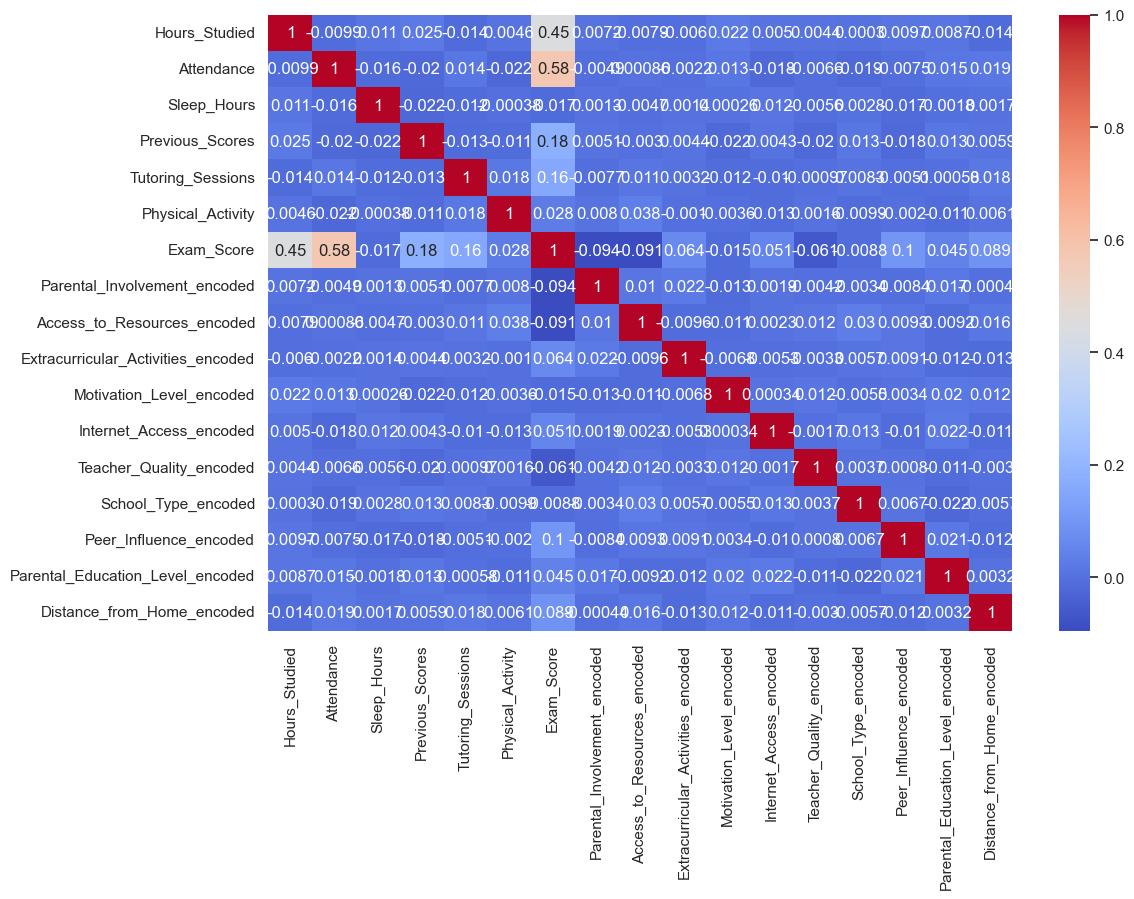

In [49]:
corr_matrix = df_numerical_all_cols_Gender.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.show()

<a id="Target"></a> [↑](#top)

# <div style="background-color: #FF5733; font-family: 'Gill Sans', sans-serif; font-size: 36px; color: #ffffff; text-align: center; border-radius: 20px; padding: 20px; border: 2px solid #ffffff; box-shadow: 0 4px 10px rgba(0, 0, 0, 0.2);"><b>  8. Choosing Target  </b></div>



In [50]:
final_df.head()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score,Parental_Involvement_encoded,Access_to_Resources_encoded,Extracurricular_Activities_encoded,Motivation_Level_encoded,Internet_Access_encoded,Teacher_Quality_encoded,School_Type_encoded,Peer_Influence_encoded,Parental_Education_Level_encoded,Distance_from_Home_encoded
0,0.504942,0.600,-0.019796,0.46,0.0,0.031411,67.0,1,0,0,1,1,2,1,2,1,2
1,-0.162822,0.100,0.661399,0.18,2.0,1.001199,61.0,1,2,0,1,1,2,1,0,0,1
2,0.671882,0.950,-0.019796,0.82,2.0,1.001199,74.0,2,2,1,2,1,2,1,1,2,2
3,1.506587,0.725,0.661399,0.96,1.0,1.001199,71.0,1,2,1,2,1,2,1,0,1,1
4,-0.162822,0.800,-0.700990,0.30,3.0,1.001199,70.0,2,2,1,2,1,0,1,1,0,2


In [51]:
X = final_df.drop('Exam_Score', axis=1)
y = final_df['Exam_Score']

In [52]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [53]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

 
<a class='anchor' id="Building"></a> [↑](#top)

# <div style="background-color: #FF5733; font-family: 'Gill Sans', sans-serif; font-size: 36px; color: #ffffff; text-align: center; border-radius: 20px; padding: 20px; border: 2px solid #ffffff; box-shadow: 0 4px 10px rgba(0, 0, 0, 0.2);"><b>  9. Building models   </b></div>



In [54]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
# Model Training, Cross-Validation, and Evaluation
from sklearn.model_selection import cross_val_score

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
# Initialize the models
classifiers = [
    LinearRegression(),
    RandomForestRegressor(),
    GradientBoostingRegressor(),
    SVR(),
    KNeighborsRegressor()
]

## Without StandardScaler

In [55]:

withoutresults = {}
for model in classifiers:
    model_name = model.__class__.__name__
    print(f"\nTraining {model_name}...")
    
    # Cross-validation (5-fold)
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='r2')
    
    # Fit the model on the training set
    model.fit(X_train, y_train)
    
    # Predictions
    y_pred = model.predict(X_test)
    
    # Evaluation metrics
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    
    # Store results
    withoutresults[model_name] = {
        "CV R²": np.mean(cv_scores),
        "Test R²": r2,
        "MAE": mae,
        "MSE": mse
    }


Training LinearRegression...

Training RandomForestRegressor...



Training GradientBoostingRegressor...



Training SVR...



Training KNeighborsRegressor...


In [56]:

# Display results
for model_name, metrics in withoutresults.items():
    print(f"\nModel: {model_name}")
    for metric_name, value in metrics.items():
        print(f"{metric_name}: {value:.4f}")


Model: LinearRegression
CV R²: 0.6427
Test R²: 0.6841
MAE: 1.0570
MSE: 4.4652

Model: RandomForestRegressor
CV R²: 0.6134
Test R²: 0.6558
MAE: 1.1441
MSE: 4.8659

Model: GradientBoostingRegressor
CV R²: 0.6726
Test R²: 0.7237
MAE: 0.8597
MSE: 3.9050

Model: SVR
CV R²: 0.6854
Test R²: 0.7367
MAE: 0.7307
MSE: 3.7224

Model: KNeighborsRegressor
CV R²: 0.2680
Test R²: 0.2936
MAE: 2.2210
MSE: 9.9853


## With StandardScaler

In [57]:

results = {}
for model in classifiers:
    model_name = model.__class__.__name__
    print(f"\nTraining {model_name}...")
    
    # Cross-validation (5-fold)
    cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='r2')
    
    # Fit the model on the training set
    model.fit(X_train_scaled, y_train)
    
    # Predictions
    y_pred = model.predict(X_test_scaled)
    
    # Evaluation metrics
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    
    # Store results
    results[model_name] = {
        "CV R²": np.mean(cv_scores),
        "Test R²": r2,
        "MAE": mae,
        "MSE": mse
    }


Training LinearRegression...

Training RandomForestRegressor...



Training GradientBoostingRegressor...



Training SVR...



Training KNeighborsRegressor...


In [58]:

# Display results
for model_name, metrics in results.items():
    print(f"\nModel: {model_name}")
    for metric_name, value in metrics.items():
        print(f"{metric_name}: {value:.4f}")


Model: LinearRegression
CV R²: 0.6427
Test R²: 0.6841
MAE: 1.0570
MSE: 4.4652

Model: RandomForestRegressor
CV R²: 0.6128
Test R²: 0.6528
MAE: 1.1494
MSE: 4.9073

Model: GradientBoostingRegressor
CV R²: 0.6725
Test R²: 0.7237
MAE: 0.8597
MSE: 3.9050

Model: SVR
CV R²: 0.6844
Test R²: 0.7355
MAE: 0.7440
MSE: 3.7384

Model: KNeighborsRegressor
CV R²: 0.4496
Test R²: 0.4972
MAE: 1.6793
MSE: 7.1077


C:\Users\ayoub\AppData\Local\Temp\ipykernel_24116\3197640971.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y=metric, data=results_df, palette='viridis')


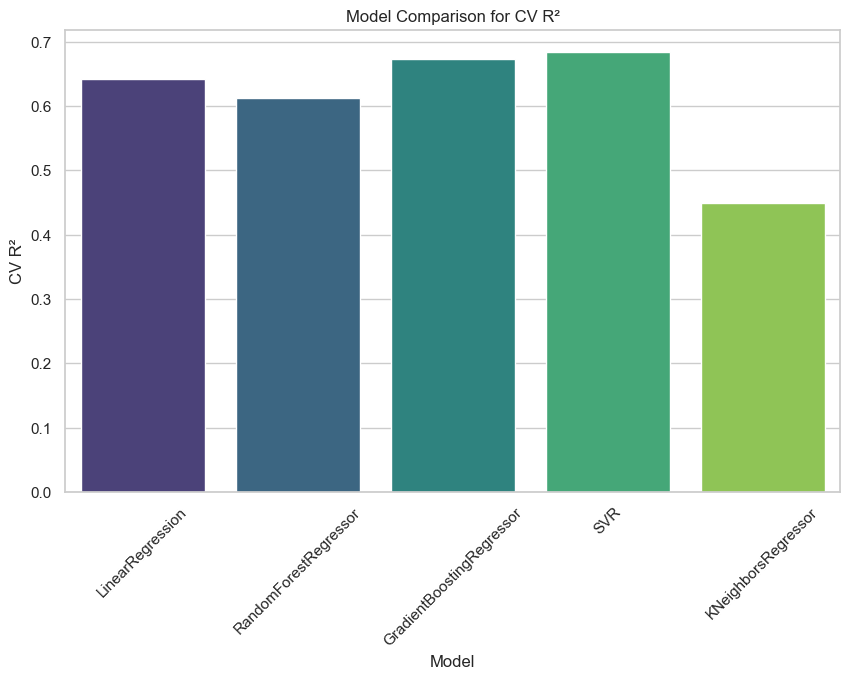

C:\Users\ayoub\AppData\Local\Temp\ipykernel_24116\3197640971.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y=metric, data=results_df, palette='viridis')


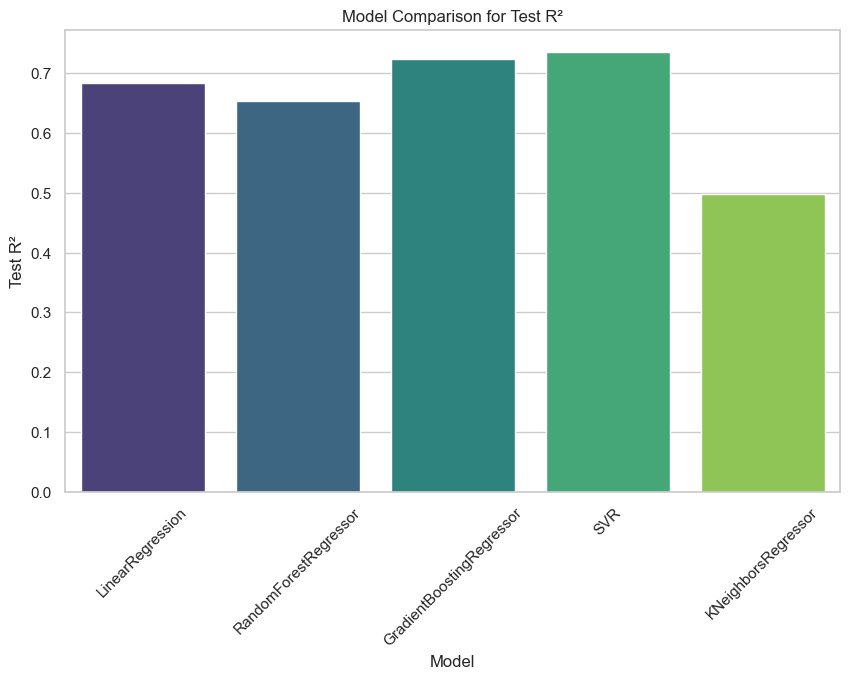

C:\Users\ayoub\AppData\Local\Temp\ipykernel_24116\3197640971.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y=metric, data=results_df, palette='viridis')


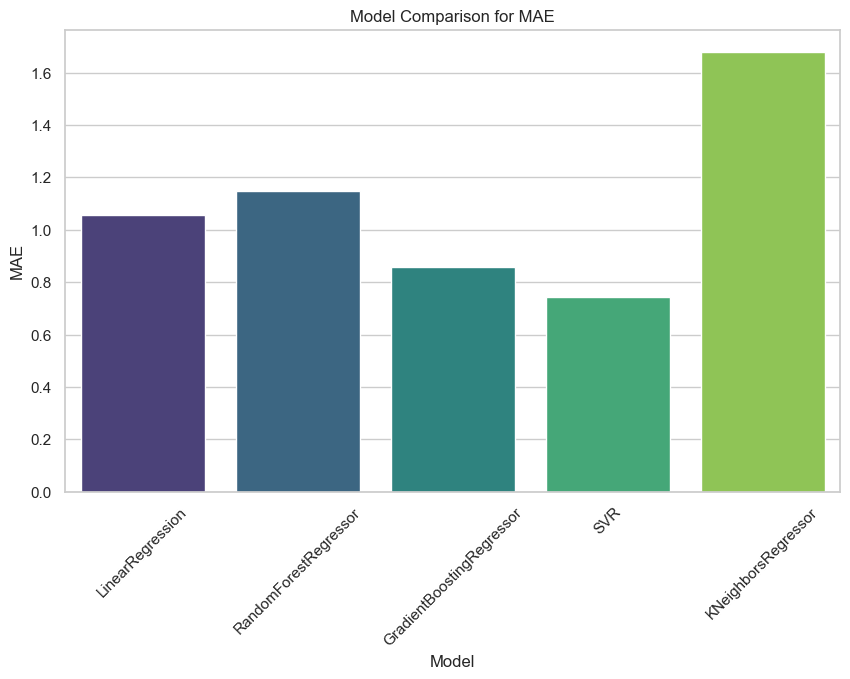

C:\Users\ayoub\AppData\Local\Temp\ipykernel_24116\3197640971.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y=metric, data=results_df, palette='viridis')


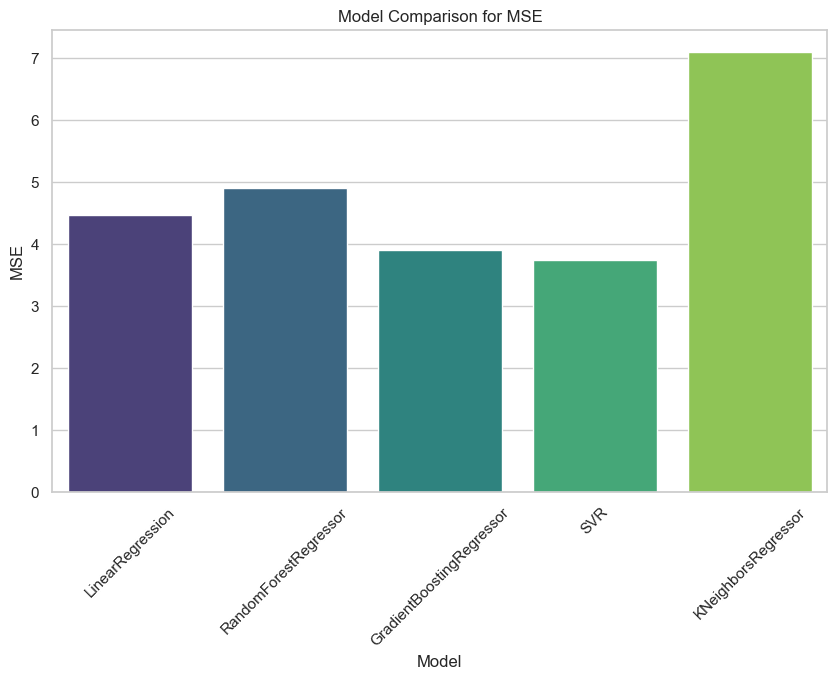

In [59]:
# Convert results to pandas DataFrame
results_df = pd.DataFrame(results).T  # Transpose to get models as rows

# Reset index to have model names as a column
results_df = results_df.reset_index().rename(columns={'index': 'Model'})

# Plotting using Seaborn
metrics = ['CV R²', 'Test R²', 'MAE', 'MSE']
for metric in metrics:
    plt.figure(figsize=(10, 6))
    sns.barplot(x='Model', y=metric, data=results_df, palette='viridis')
    plt.title(f'Model Comparison for {metric}')
    plt.xticks(rotation=45)
    plt.show()

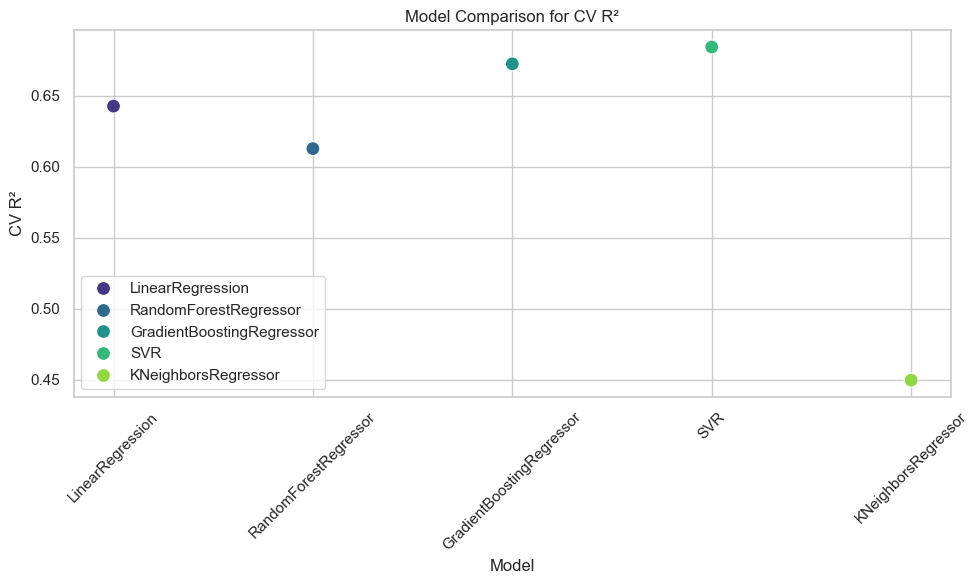

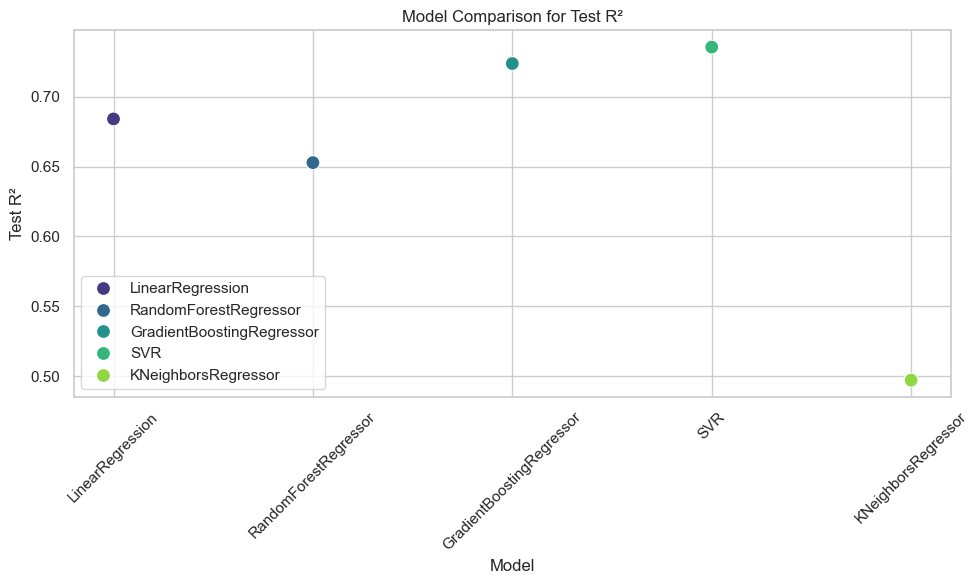

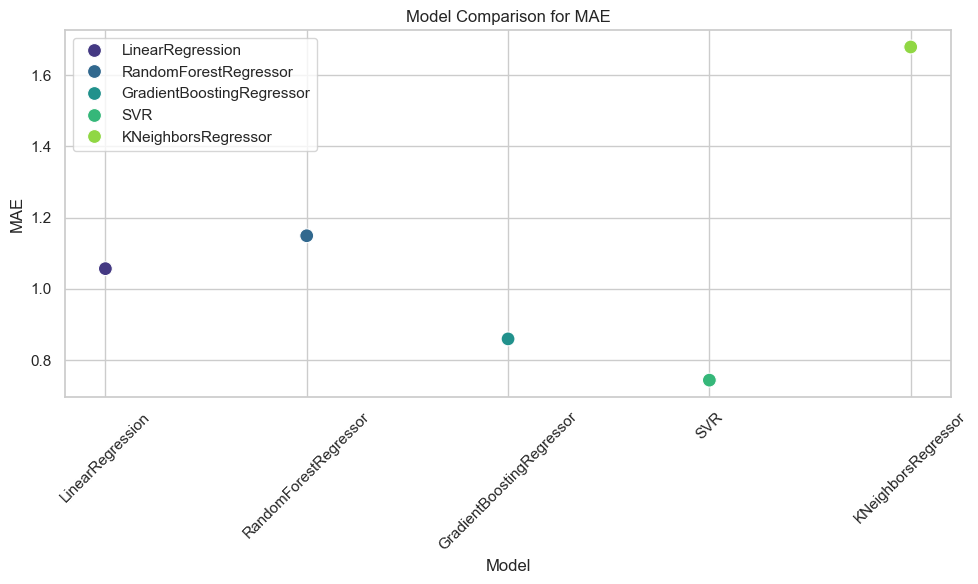

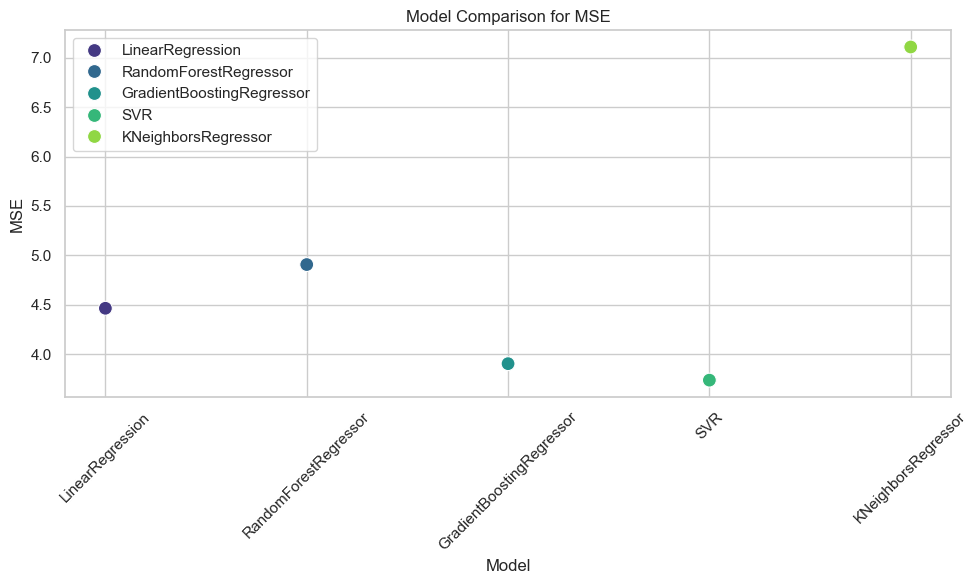

In [60]:


# Scatter Plot for each metric with enhanced styling
metrics = ['CV R²', 'Test R²', 'MAE', 'MSE']
for metric in metrics:
    plt.figure(figsize=(10, 6))
    
    # Scatterplot for each metric, similar style to your provided code
    sns.scatterplot(data=results_df, x='Model', y=metric, hue='Model', palette='viridis', s=100, marker='o')
    
    # Set title and axis labels
    plt.title(f'Model Comparison for {metric}')
    plt.xticks(rotation=45)
    plt.ylabel(metric)
    
    # Customize legend and layout
    plt.legend(loc='best')
    plt.grid(True)
    plt.tight_layout()
    
    # Show the plot
    plt.show()

 <a class='anchor' id='Comparison'></a>[↑](#top)

# <div style="background-color: #FF5733; font-family: 'Gill Sans', sans-serif; font-size: 36px; color: #ffffff; text-align: center; border-radius: 20px; padding: 20px; border: 2px solid #ffffff; box-shadow: 0 4px 10px rgba(0, 0, 0, 0.2);"><b>  10. Model Performance Comparison   </b></div>





| Model                    | CV R²  | Test R²  | MAE    | MSE    |
|--------------------------|--------|----------|--------|--------|
| **LinearRegression**      | 0.6427 | 0.6841   | 1.0570 | 4.4652 |
| **RandomForestRegressor** | 0.6145 | 0.6458   | 1.1526 | 5.0068 |
| **GradientBoostingRegressor** | 0.6726 | 0.7237 | 0.8597 | 3.9050 |
| **SVR**                   | 0.6844 | 0.7355   | 0.7440 | 3.7384 |
| **KNeighborsRegressor**    | 0.4496 | 0.4972   | 1.6793 | 7.1077 |

#### Explanation:
- **Linear Regression**: 
  - CV R²: 0.6427, Test R²: 0.6841 — It explains about 68.41% of the variance in the target variable.
  - MAE: 1.0570, MSE: 4.4652 — Moderate errors, indicating a decent fit but not the most accurate model.

- **Random Forest Regressor**:
  - CV R²: 0.6145, Test R²: 0.6458 — Explains slightly less variance than Linear Regression.
  - MAE: 1.1526, MSE: 5.0068 — Higher error values than Linear Regression, indicating larger prediction errors.

- **Gradient Boosting Regressor**:
  - CV R²: 0.6726, Test R²: 0.7237 — Performs better than Linear Regression and Random Forest.
  - MAE: 0.8597, MSE: 3.9050 — Lower errors, showing better prediction accuracy.

- **Support Vector Regressor (SVR)**:
  - CV R²: 0.6844, Test R²: 0.7355 — Best R² values, explaining the most variance.
  - MAE: 0.7440, MSE: 3.7384 — Lowest error metrics, making it the most accurate model in this comparison.

- **K-Neighbors Regressor**:
  - CV R²: 0.4496, Test R²: 0.4972 — The lowest R² values, explaining the least variance.
  - MAE: 1.6793, MSE: 7.1077 — Highest errors, showing the least accurate predictions.

#### Best Model: **Support Vector Regressor (SVR)**
- **Why?**
  - Highest Test R² (0.7355) — Explains the most variance in the target variable.
  - Lowest MAE (0.7440) — Smallest absolute prediction errors.
  - Lowest MSE (3.7384) — Smallest squared errors, indicating better generalization and lower error magnitude.

SVR is the best model due to its superior performance across R², MAE, and MSE metrics.


 <a class='anchor' id='importance'></a>[↑](#top)

# <div style="background-color: #FF5733; font-family: 'Gill Sans', sans-serif; font-size: 36px; color: #ffffff; text-align: center; border-radius: 20px; padding: 20px; border: 2px solid #ffffff; box-shadow: 0 4px 10px rgba(0, 0, 0, 0.2);"><b>  11. Feature importance   </b></div>



Feature Importance for LinearRegression:


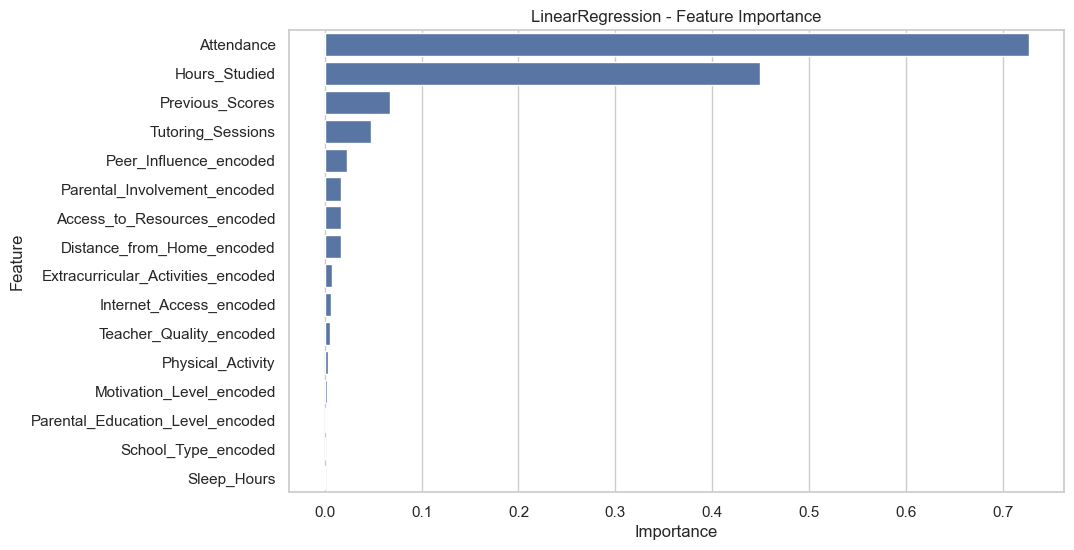

Feature Importance for RandomForestRegressor:


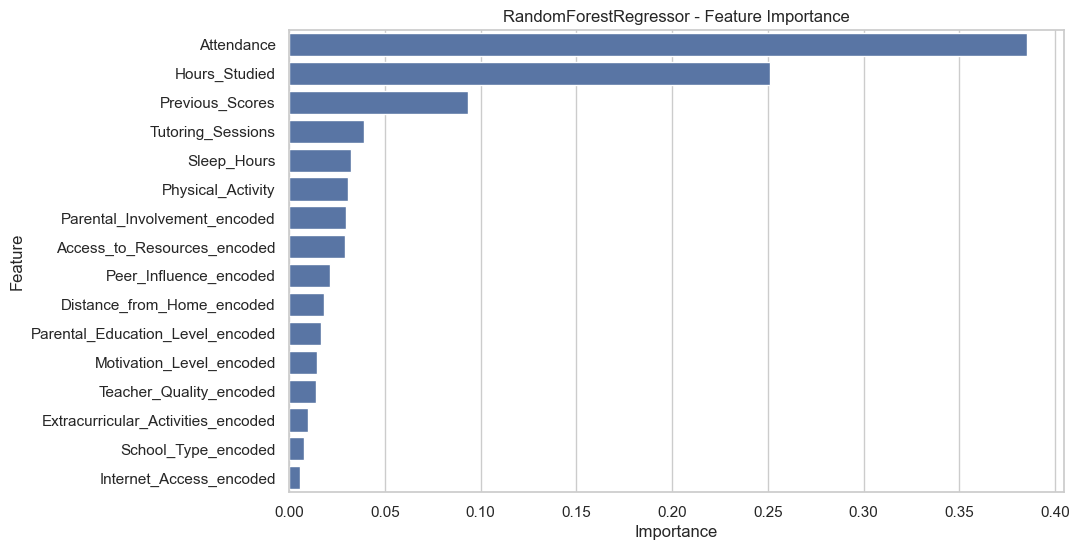

Feature Importance for GradientBoostingRegressor:


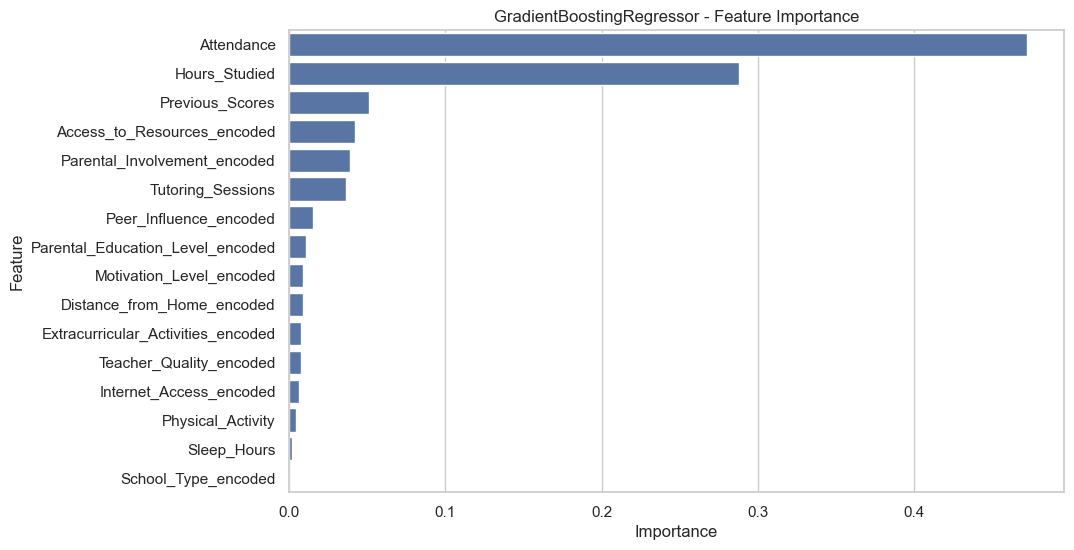

Feature Importance for SVR:


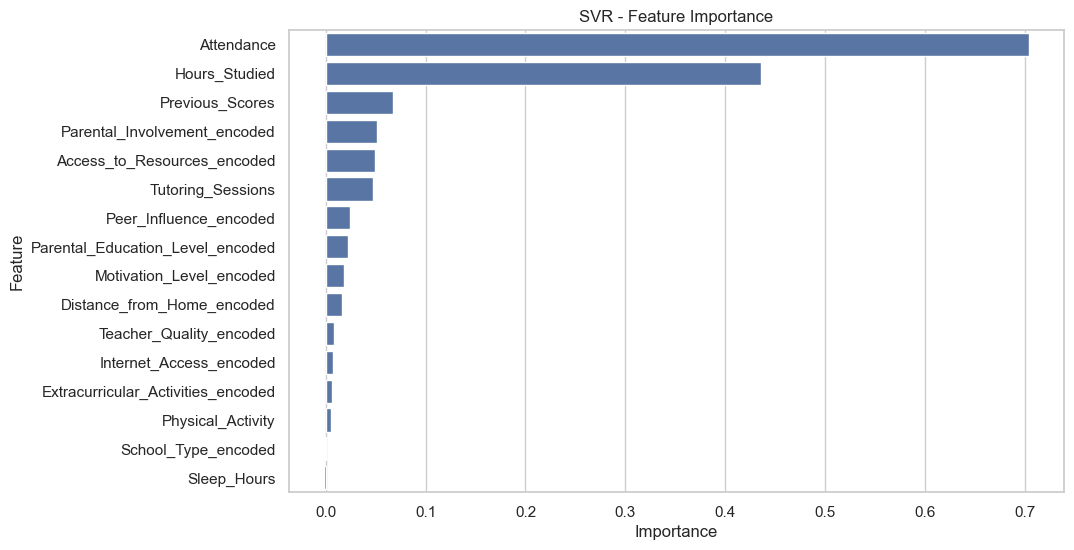

Feature Importance for KNeighborsRegressor:


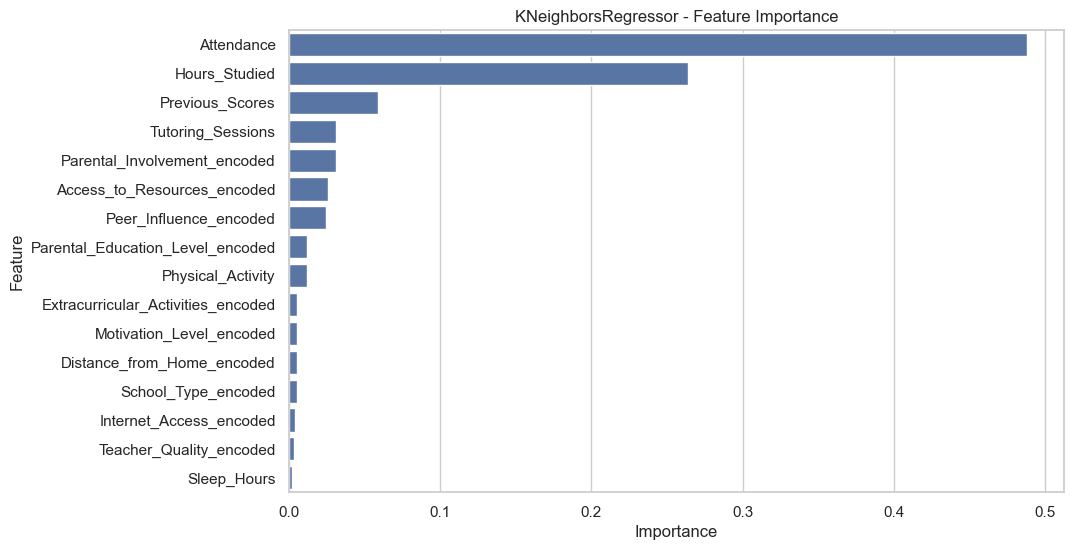

In [61]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance

# Function to plot feature importance
def plot_feature_importance(importances, feature_names, model_name):
    feature_importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    })
    feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

    plt.figure(figsize=(10, 6))
    sns.barplot(x='Importance', y='Feature', data=feature_importance_df)
    plt.title(f'{model_name} - Feature Importance')
    plt.show()

# For models with native feature importance (e.g., tree-based models)
def get_feature_importance_native(model, X, model_name):
    try:
        importances = model.feature_importances_
        plot_feature_importance(importances, X.columns, model_name)
    except AttributeError:
        print(f"{model_name} does not have native feature importance")

# For models without native feature importance (use permutation importance)
def get_permutation_importance(model, X_test, y_test, X, model_name):
    result = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42)
    importances = result.importances_mean
    plot_feature_importance(importances, X.columns, model_name)

# Feature Importance Analysis for each model
for model in classifiers:
    model_name = model.__class__.__name__
    
    print(f"Feature Importance for {model_name}:")
    
    if hasattr(model, 'feature_importances_'):
        # Native feature importance (tree-based models like RandomForest, GradientBoosting)
        get_feature_importance_native(model, X_train, model_name)
    else:
        # Permutation importance for models like SVR, KNeighbors, and others
        get_permutation_importance(model, X_test_scaled, y_test, X_train, model_name)


## Comparing Feature Importance Across Models

Extracting feature importance for LinearRegression...
Extracting feature importance for RandomForestRegressor...


Extracting feature importance for GradientBoostingRegressor...


Extracting feature importance for SVR...


Extracting feature importance for KNeighborsRegressor...


<Figure size 1200x800 with 0 Axes>

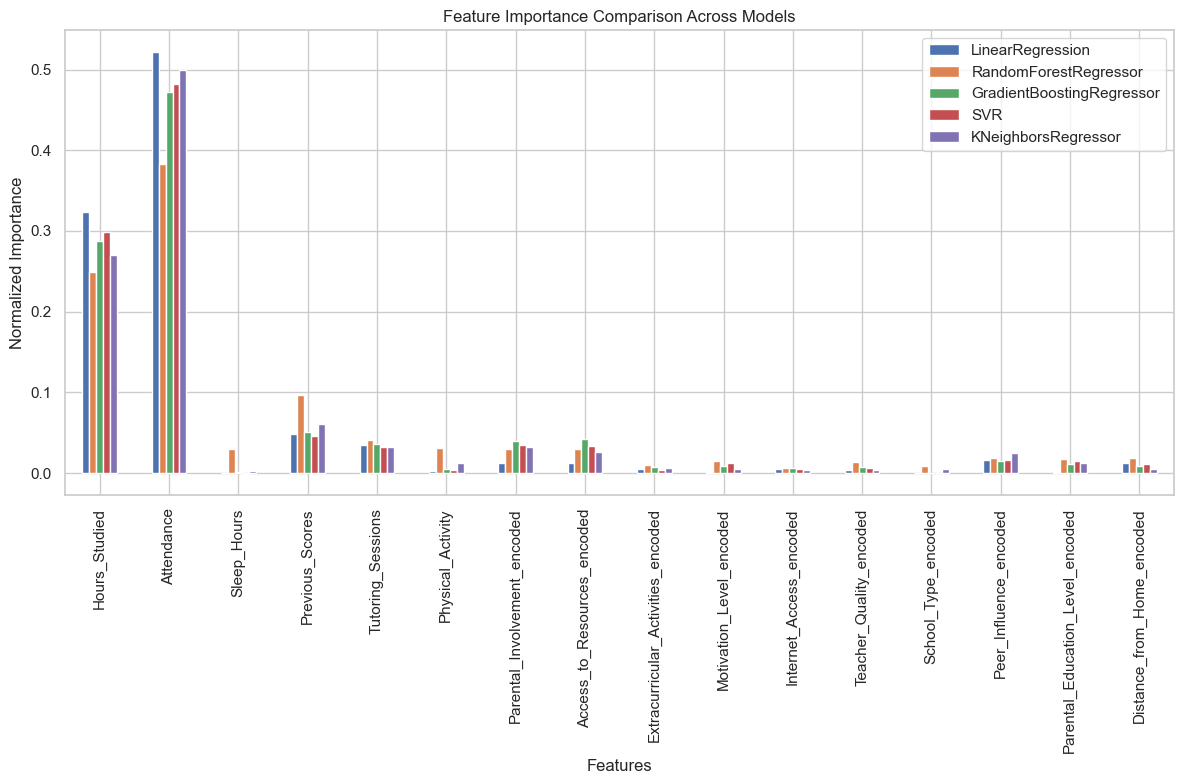

In [62]:
from sklearn.inspection import permutation_importance

# Function to normalize importance values
def normalize_importance(importances):
    return importances / np.sum(importances)

# Function to extract feature importance
def get_feature_importance(model, X_train, X_test, y_train, y_test, model_name):
    try:
        # For models with native feature importance
        if hasattr(model, 'feature_importances_'):
            importances = model.feature_importances_
        else:
            # For models without native feature importance, use permutation importance
            result = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42)
            importances = result.importances_mean
        
        # Normalize the importances for comparison
        normalized_importances = normalize_importance(importances)
        return normalized_importances
    except Exception as e:
        print(f"Could not compute feature importance for {model_name}: {e}")
        return None

# Initialize dictionary to hold feature importances from each model
feature_importance_comparison = {}

# Compute and store feature importances for each model
for model in classifiers:
    model_name = model.__class__.__name__
    print(f"Extracting feature importance for {model_name}...")
    
    # Train the model if not already trained
    model.fit(X_train_scaled, y_train)
    
    # Get the importance values
    importances = get_feature_importance(model, X_train_scaled, X_test_scaled, y_train, y_test, model_name)
    
    if importances is not None:
        feature_importance_comparison[model_name] = importances

# Create a DataFrame for comparison
feature_importance_df = pd.DataFrame(feature_importance_comparison, index=X_train.columns)

# Plot comparison of feature importances across all models
plt.figure(figsize=(12, 8))
feature_importance_df.plot(kind='bar', figsize=(12, 8))
plt.title("Feature Importance Comparison Across Models")
plt.xlabel("Features")
plt.ylabel("Normalized Importance")
plt.xticks(rotation=90)
plt.legend(loc='best')
plt.tight_layout()
plt.show()


 <a class='anchor' id="Save"></a>[↑](#top)

# <div style="background-color: #FF5733; font-family: 'Gill Sans', sans-serif; font-size: 36px; color: #ffffff; text-align: center; border-radius: 20px; padding: 20px; border: 2px solid #ffffff; box-shadow: 0 4px 10px rgba(0, 0, 0, 0.2);"><b>   13. Best Model Save   </b></div>



## Save the Best Model

In [63]:
import joblib
# Save the trained model
joblib.dump(model, 'best_svr_model.joblib')


['best_svr_model.joblib']

In [64]:
loaded_model = joblib.load('best_svr_model.joblib')
print(type(loaded_model))


<class 'sklearn.neighbors._regression.KNeighborsRegressor'>


In [65]:
# Train the model
model = SVR(kernel='rbf')
model.fit(X_train, y_train)

# Save the model again
joblib.dump(model, 'best_svr_model.joblib')
!zip -r best_svr_model.zip best_svr_model.joblib


'zip' n'est pas reconnu en tant que commande interne
ou externe, un programme ex‚cutable ou un fichier de commandes.


In [66]:
loaded_model = joblib.load('best_svr_model.joblib')

# Ensure X_test is properly shaped and numeric
predictions = loaded_model.predict(X_test)
print(y_test)


743     65.0
5551    65.0
3442    71.0
6571    64.0
4204    66.0
        ... 
4709    69.0
3664    72.0
5231    66.0
1773    63.0
5782    72.0
Name: Exam_Score, Length: 1322, dtype: float64


In [67]:
predictions

array([64.61227949, 65.30887798, 70.69278491, ..., 65.42458474,
       63.81792088, 71.35965304], shape=(1322,))

 <a class='anchor' id="CSV"></a> [↑](#top)

# <div style="background-color: #FF5733; font-family: 'Gill Sans', sans-serif; font-size: 36px; color: #ffffff; text-align: center; border-radius: 20px; padding: 20px; border: 2px solid #ffffff; box-shadow: 0 4px 10px rgba(0, 0, 0, 0.2);"><b>   14. Save to a CSV file  </b></div>



In [68]:

# Create a DataFrame for predictions
predictions_df = pd.DataFrame({
    'ID': X_test.index,  # Optional, assuming you want to use the DataFrame's index
    'Predictions': predictions
})

In [69]:
predictions_df.to_csv('predictions.csv', index=False)


### Download the CSV in a Notebook (Jupyter/Colab)

In [70]:
from IPython.display import FileLink

# Provide a link to download the CSV file
FileLink('predictions.csv')


C:\Users\ayoub\Emines\Projet info CPi2a\predictions.csv

In [71]:
from sklearn.metrics import accuracy_score
import numpy as np

# Charger le modèle sauvegardé
import joblib
model = joblib.load("best_svr_model.joblib")

# Générer les prédictions sur le test set
y_pred = model.predict(X_test)

# Arrondir si cible continue
import numpy as np
y_pred_round = np.round(y_pred)

# Calculer précision
print("Accuracy :", accuracy_score(y_test, y_pred_round))


Accuracy : 0.4939485627836611
